Final code: Code to improve accuracy from 94.60% on test set

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# BTTypes dataset described in Table 3 of the paper.
image_dir = Path('/Users/kaivalyapuranik/Downloads/archive')

filepaths = list(image_dir.glob(r'**/*.png'))
labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepaths))

filepaths = pd.Series(filepaths, name='Filepath').astype(str)
labels = pd.Series(labels, name='Label')
image_df = pd.concat([filepaths, labels], axis=1)
image_df = image_df.sample(frac=1, random_state=1).reset_index(drop=True)

# Paper split: 70% train, 15% validation, 15% test.
train_df, temp_df = train_test_split(
    image_df,
    train_size=0.7,
    shuffle=True,
    random_state=1
)
val_df, test_df = train_test_split(
    temp_df,
    train_size=0.5,
    shuffle=True,
    random_state=1
)

# BTTypes is already the augmented 2,400-image dataset; use preprocessing only.
def create_gen():
    image_generator = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
    )

    common_args = {
        'target_size': (224, 224),
        'color_mode': 'rgb',
        'class_mode': 'categorical',
        'batch_size': 16
    }
    train_images = image_generator.flow_from_dataframe(
        dataframe=train_df,
        x_col='Filepath',
        y_col='Label',
        shuffle=True,
        seed=0,
        **common_args
    )
    val_images = image_generator.flow_from_dataframe(
        dataframe=val_df,
        x_col='Filepath',
        y_col='Label',
        shuffle=False,
        **common_args
    )
    test_images = image_generator.flow_from_dataframe(
        dataframe=test_df,
        x_col='Filepath',
        y_col='Label',
        shuffle=False,
        **common_args
    )
    return train_images, val_images, test_images

train_images, val_images, test_images = create_gen()

# Remove MobileNetV2's original classification head and retain GAP output.
pretrained_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)

# Paper: freeze all MobileNetV2 layers except the last 50.
pretrained_model.trainable = True
for layer in pretrained_model.layers[:-50]:
    layer.trainable = False

# Paper custom head: Dense/ReLU, BatchNormalization, Dropout, repeated twice,
# followed by the softmax class output.
inputs = pretrained_model.input
x = pretrained_model.output
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.5)(x)
outputs = tf.keras.layers.Dense(
    len(image_df['Label'].unique()),
    activation='softmax'
)(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# BTTypes hyperparameters from paper Table 5.
history = model.fit(
    train_images,
    validation_data=val_images,
    batch_size=16,
    epochs=10
)

print(f'Input shape: {model.input_shape}; output classes: {model.output_shape[-1]}')

Found 1680 validated image filenames belonging to 2 classes.
Found 360 validated image filenames belonging to 2 classes.
Found 360 validated image filenames belonging to 2 classes.
Epoch 1/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 39s 305ms/step - accuracy: 0.8976 - loss: 0.2793 - val_accuracy: 0.8444 - val_loss: 0.9582
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 32s 305ms/step - accuracy: 0.9708 - loss: 0.0917 - val_accuracy: 0.5833 - val_loss: 6.5091
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 32s 302ms/step - accuracy: 0.9756 - loss: 0.0694 - val_accuracy: 0.9556 - val_loss: 0.2649
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 32s 302ms/step - accuracy: 0.9869 - loss: 0.0345 - val_accuracy: 0.9917 - val_loss: 0.0389
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 31s 297ms/step - accuracy: 0.9887 - loss: 0.0385 - val_accuracy: 0.9694 - val_loss: 0.2483
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 31s 299ms/step - accuracy: 0.9845 - loss: 0.0513 - val_accuracy: 0.9833 - val_loss: 0.0682
Epoch 7/10
105/105 ━━━━━━━━━━━━━━

In [2]:
model.save('/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/BTTypes_MobileNetV2.keras')
print("Model saved successfully.")

Model saved successfully.


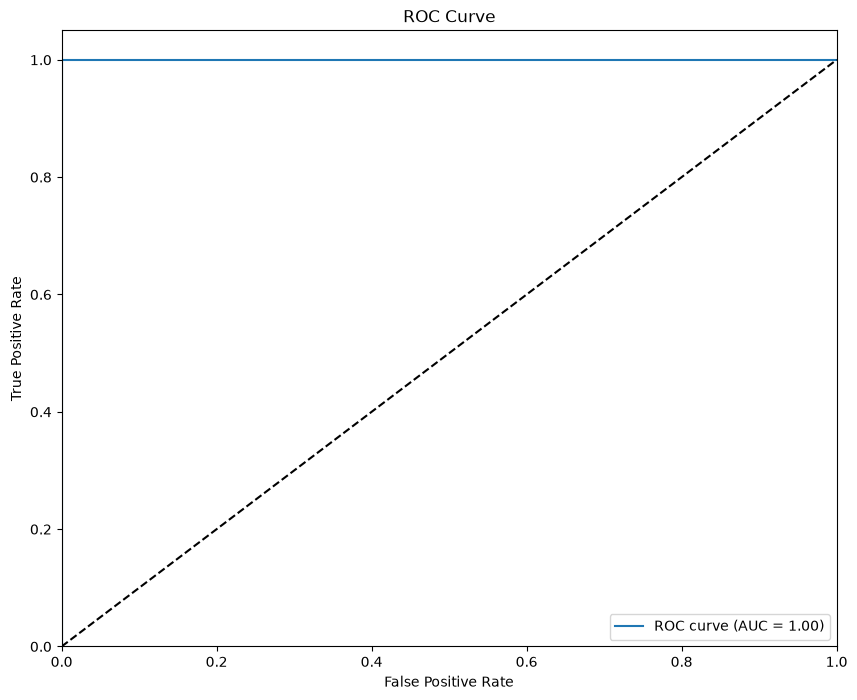

AUC: 1.0


In [2]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Actual labels
y_true = test_images.classes

# Predicted probabilities
y_pred_proba = model.predict(test_images, verbose=0)

# Probability of class 1 (positive class)
y_score = y_pred_proba[:, 1]

# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

print("AUC:", roc_auc)

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step
              precision    recall  f1-score   support

      Benign       1.00      0.99      1.00       172
   Malignant       0.99      1.00      1.00       188

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360



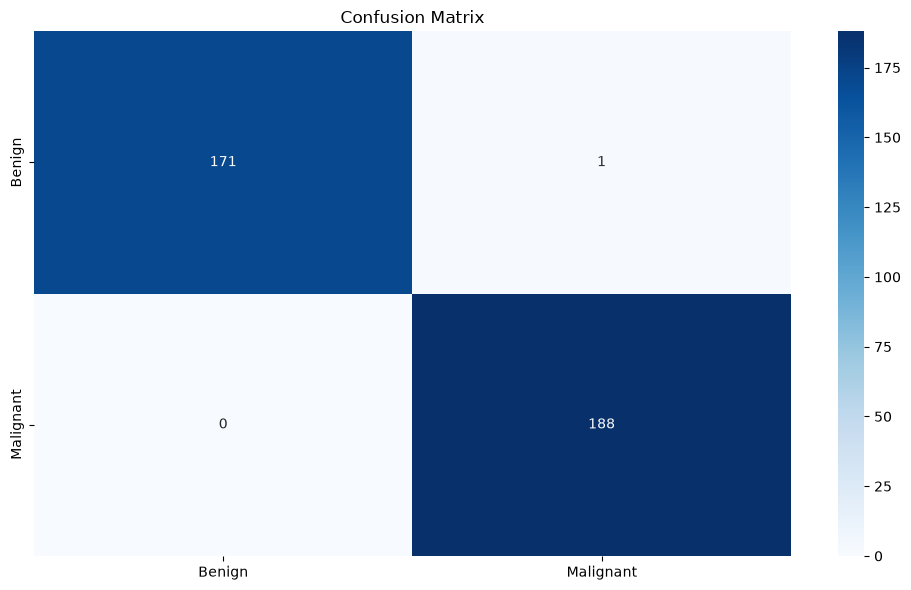

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions
pred = model.predict(test_images)
pred = np.argmax(pred, axis=1)

# Map the label
labels = (train_images.class_indices)  # Assuming train_images is a data generator
labels = dict((v, k) for k, v in labels.items())  # Reverse the dictionary to get label mapping
pred = [labels[k] for k in pred]

# Assuming your test_df contains true labels for comparison
y_test = list(test_df['Label'])  # Replace 'Label' with the actual column name containing true labels

# Evaluation Metrics
print(classification_report(y_test, pred))

# Confusion matrix
cf_matrix = confusion_matrix(y_test, pred)

# Create the confusion matrix plot
plt.figure(figsize=(10, 6))
sns.heatmap(cf_matrix, annot=True, fmt='d', xticklabels=sorted(set(y_test)), yticklabels=sorted(set(y_test)), cmap="Blues")
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()


Saving model

In [4]:
# Save the trained model
#keras.saving.save_model(model, 'my_model.keras')

Deep Feature extraction like i extracted in matlab 

In [5]:
import os
import pickle
import numpy as np
from tensorflow.keras.models import Model

# Paper: extract from the fourth-last layer, the second dense layer.
loaded_model = model
feature_extractor = Model(
    inputs=loaded_model.input,
    outputs=loaded_model.layers[-4].output
)

feature_dir = 'extracted_features_BTTypes'
os.makedirs(feature_dir, exist_ok=True)

def extract_features(data_gen, set_name):
    features = []
    labels = []

    # No additional random augmentation during feature extraction.
    data_gen.reset()
    for _ in range(len(data_gen)):
        batch_images, batch_labels = next(data_gen)
        batch_features = feature_extractor.predict(batch_images, verbose=0)
        features.append(batch_features)
        labels.append(batch_labels)

    features = np.concatenate(features, axis=0)
    labels = np.concatenate(labels, axis=0)

    with open(os.path.join(feature_dir, f'{set_name}_features.pkl'), 'wb') as file:
        pickle.dump((features, labels), file)

    print(
        f'{set_name}: features shape = {features.shape}, '
        f'labels shape = {labels.shape}'
    )

extract_features(train_images, 'train')
extract_features(val_images, 'val')
extract_features(test_images, 'test')

print('BTTypes features extracted and saved.')

train: features shape = (1680, 128), labels shape = (1680, 2)
val: features shape = (360, 128), labels shape = (360, 2)
test: features shape = (360, 128), labels shape = (360, 2)
BTTypes features extracted and saved.


Classification of features using saved extracted features

In [6]:
# # Import necessary libraries
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pickle
import os
import numpy as np

# Directory to save extracted features and models
feature_dir = 'extracted_features_BTTypes'
model_dir = 'saved_models'
os.makedirs(model_dir, exist_ok=True)

# Load extracted features
with open(os.path.join(feature_dir, "train_features.pkl"), 'rb') as f:
    train_features, train_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "val_features.pkl"), 'rb') as f:
    val_features, val_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "test_features.pkl"), 'rb') as f:
    test_features, test_labels = pickle.load(f)

# Convert one-hot encoded labels to single-class labels
train_labels = np.argmax(train_labels, axis=1)
val_labels = np.argmax(val_labels, axis=1)
test_labels = np.argmax(test_labels, axis=1)

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=0)
clf.fit(train_features, train_labels)

# Save the trained Decision Tree model
tree_model_path = os.path.join(model_dir, 'decision_tree_model.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(clf, f)

# Evaluate on training, validation, and test sets
for set_name, features, labels in [("Train", train_features, train_labels), ("Validation", val_features, val_labels), ("Test", test_features, test_labels)]:
    predictions = clf.predict(features)
    accuracy = accuracy_score(labels, predictions)
    print(f"{set_name} Accuracy: {accuracy * 100:.2f}%")
    print(f"{set_name} Confusion Matrix:\n", confusion_matrix(labels, predictions))
    print(f"{set_name} Classification Report:\n", classification_report(labels, predictions))

print(f"Decision Tree model saved to: {tree_model_path}")


Train Accuracy: 100.00%
Train Confusion Matrix:
 [[854   0]
 [  0 826]]
Train Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       854
           1       1.00      1.00      1.00       826

    accuracy                           1.00      1680
   macro avg       1.00      1.00      1.00      1680
weighted avg       1.00      1.00      1.00      1680

Validation Accuracy: 99.72%
Validation Confusion Matrix:
 [[173   1]
 [  0 186]]
Validation Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00       174
           1       0.99      1.00      1.00       186

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360

Test Accuracy: 100.00%
Test Confusion Matrix:
 [[172   0]
 [  0 188]]
Test Classification Report:
               precision    re

In [7]:
from sklearn.tree import export_text
import pickle

# Load the trained decision tree model
with open(tree_model_path, 'rb') as f:
    clf = pickle.load(f)

# Extract decision rules
tree_rules = export_text(clf, feature_names=[f'feature_{i}' for i in range(train_features.shape[1])])

# Display decision rules
print("Extracted Decision Tree Rules:\n")
print(tree_rules)


Extracted Decision Tree Rules:

|--- feature_12 <= 1.52
|   |--- class: 0
|--- feature_12 >  1.52
|   |--- class: 1



USing Rulefit on the extracted deep features

In [8]:
import os
import pickle
import numpy as np
%pip install rulefit
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix

# Directory to save extracted features and models
feature_dir = 'extracted_features_BTTypes'
model_dir = 'saved_models'
os.makedirs(model_dir, exist_ok=True)

# Load extracted features
with open(os.path.join(feature_dir, "train_features.pkl"), 'rb') as f:
    train_features, train_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "val_features.pkl"), 'rb') as f:
    val_features, val_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "test_features.pkl"), 'rb') as f:
    test_features, test_labels = pickle.load(f)

# Check shapes of features and labels
print("Train Features Shape:", train_features.shape)
print("Train Labels Shape:", train_labels.shape)
print("Validation Features Shape:", val_features.shape)
print("Validation Labels Shape:", val_labels.shape)

# Ensure labels are aligned with features
assert train_features.shape[0] == train_labels.shape[0], "Mismatch between train features and labels."
assert val_features.shape[0] == val_labels.shape[0], "Mismatch between validation features and labels."

# Convert multi-dimensional labels to single class labels (if needed)
train_labels = np.argmax(train_labels, axis=1)  # Assuming one-hot encoding
val_labels = np.argmax(val_labels, axis=1)      # Assuming one-hot encoding
test_labels = np.argmax(test_labels, axis=1)    # If test labels are also one-hot encoded

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding or using a threshold
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Save rules to a text file
output_file_path = os.path.join(
    model_dir,
    'rulefit_rules_on_deep_features_BTTypes.txt'
)


Note: you may need to restart the kernel to use updated packages.
Train Features Shape: (1680, 128)
Train Labels Shape: (1680, 2)
Validation Features Shape: (360, 128)
Validation Labels Shape: (360, 2)
Combined Training + Validation Features Shape: (2040, 128)
Combined Training + Validation Labels Shape: (2040,)
Testing Accuracy: 1.0000
Confusion Matrix:
[[172   0]
 [  0 188]]
Top Rules from RuleFit Model:
                                                  rule  type      coef  \
282                   feature_21 <= 3.1873998641967773  rule -0.420128   
140                   feature_12 <= 2.4066677689552307  rule -0.225877   
151                    feature_12 > 1.8264159560203552  rule  0.185103   
261                    feature_89 > 1.1488544791936874  rule  0.058322   
192  feature_21 <= 3.2080729007720947 & feature_6 >...  rule -0.038874   

      support  importance  
282  0.494595    0.210052  
140  0.540541    0.112567  
151  0.505405    0.092546  
261  0.486486    0.029150  
192  

/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.236507e-01, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


Calculate Statistical Features for Training, Validation, and Testing Sets

In [9]:
import numpy as np
import pandas as pd
from scipy.stats import skew, entropy
import os

# Load extracted features
feature_dir = 'extracted_features_BTTypes'
stat_feature_dir = 'statistical_features_BTTypes'


os.makedirs(stat_feature_dir, exist_ok=True)

with open(os.path.join(feature_dir, "train_features.pkl"), 'rb') as f:
    train_features, train_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "val_features.pkl"), 'rb') as f:
    val_features, val_labels = pickle.load(f)
    
with open(os.path.join(feature_dir, "test_features.pkl"), 'rb') as f:
    test_features, test_labels = pickle.load(f)

# Function to calculate statistical features
def calculate_statistical_features(features):
    stats_features = []
    for f in features:
        stats = {
            'mean': np.mean(f),
            'std_dev': np.std(f),
            'skewness': skew(f),
            'variance': np.var(f),
            'median': np.median(f),
            'range': np.ptp(f),  # Peak-to-peak range
            'entropy': entropy(np.abs(f) + 1e-6),  # Add small constant to avoid log(0)
            'energy': np.sum(f ** 2),
            'contrast': np.std(f) ** 2,  # Contrast as variance
            'mean_abs_dev': np.mean(np.abs(f - np.mean(f)))
        }
        stats_features.append(stats)
    return pd.DataFrame(stats_features)

# Convert labels to 1D if necessary (e.g., if labels are one-hot encoded)
def convert_labels_to_1d(labels):
    if len(labels.shape) > 1 and labels.shape[1] > 1:
        # Assuming the labels are one-hot encoded, convert to single-class labels
        return np.argmax(labels, axis=1)
    return labels

# Calculate and save statistical features in CSV files
for set_name, features, labels in [("train", train_features, train_labels), 
                                   ("val", val_features, val_labels), 
                                   ("test", test_features, test_labels)]:
    stats_features_df = calculate_statistical_features(features)
    labels_1d = convert_labels_to_1d(labels)  # Ensure labels are 1D
    stats_features_df['label'] = labels_1d  # Append 1D labels to the DataFrame
    csv_file_path = os.path.join(stat_feature_dir, f"{set_name}_stat_features.csv")
    stats_features_df.to_csv(csv_file_path, index=False)

print("Statistical features calculated and saved to CSV files.")


Statistical features calculated and saved to CSV files.


Code for evaluating the statistical features (Mutual information and feature importance appraoch)
I used Mutual Information and Feature Importance to directly assess how well your statistical features relate to the class labels. If many features have low MI scores or feature importance values close to zero, they may not be contributing to the classification, and we might need to generate new features or revisit the feature extraction method.


In [10]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_classif

# Load the statistical features and labels from CSV
stat_feature_dir = 'statistical_features_BTTypes'

# Load the CSV file
train_df = pd.read_csv(f"{stat_feature_dir}/train_stat_features.csv")

# Separate features and labels
train_features = train_df.drop(columns=['label']).values  # Drop the 'label' column to get features
train_labels = train_df['label'].values  # Extract the labels

# Names of the statistical features (based on the columns in the CSV)
stat_feature_names = train_df.columns[:-1]  # All columns except 'label' are feature names

# 1. Mutual Information (MI) for each feature
# Mutual Information helps to see which features carry the most information about the target
mi_scores = mutual_info_classif(train_features, train_labels, discrete_features=False)
mi_scores_df = pd.DataFrame({'Feature': stat_feature_names, 'MI Score': mi_scores})
mi_scores_df.sort_values(by='MI Score', ascending=False, inplace=True)

# Display MI scores for each feature
print(mi_scores_df)


        Feature  MI Score
6       entropy  0.480635
2      skewness  0.414692
4        median  0.375542
0          mean  0.129035
1       std_dev  0.091133
3      variance  0.091043
8      contrast  0.091043
9  mean_abs_dev  0.078110
7        energy  0.071315
5         range  0.046437


Code for evaluating the statistical features (Calculate Information Gain)

In [11]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

# Load the statistical features and labels from CSV
stat_feature_dir = '/Users/kaivalyapuranik/Downloads/XAI-Med-Images-Stat-Visual-Rules BACKUP/statistical_features_BTTypes'

# Load the CSV file
train_df = pd.read_csv(f"{stat_feature_dir}/train_stat_features.csv")

# Separate features and labels
train_features = train_df.drop(columns=['label']).values  # Drop the 'label' column to get features
train_labels = train_df['label'].values  # Extract the labels

# Names of the statistical features (based on the columns in the CSV)
stat_feature_names = train_df.columns[:-1]  # All columns except 'label' are feature names

# 1. Calculate Information Gain using Decision Tree
# DecisionTreeClassifier uses information gain (or Gini impurity by default) for splits
decision_tree = DecisionTreeClassifier(criterion='entropy', random_state=42)  # Use 'entropy' to calculate information gain
decision_tree.fit(train_features, train_labels)

# Get feature importance (Information Gain for each feature)
information_gain = decision_tree.feature_importances_

# Create a DataFrame to display feature names with their respective Information Gain scores
info_gain_df = pd.DataFrame({'Feature': stat_feature_names, 'Information Gain': information_gain})
info_gain_df.sort_values(by='Information Gain', ascending=False, inplace=True)

# Display Information Gain for each feature
print(info_gain_df)


        Feature  Information Gain
4        median          0.792073
2      skewness          0.130879
5         range          0.028367
9  mean_abs_dev          0.023965
1       std_dev          0.006820
0          mean          0.005127
6       entropy          0.004498
7        energy          0.004316
8      contrast          0.002500
3      variance          0.001454


Load Statistical Features and Train & Evaluate Decision Tree Classifier

In [13]:
import os
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define the directory containing the CSV files
stat_feature_dir = 'statistical_features_BTTypes'


# Load the CSV files
train_df = pd.read_csv(os.path.join(stat_feature_dir, "train_stat_features.csv"))
val_df = pd.read_csv(os.path.join(stat_feature_dir, "val_stat_features.csv"))
test_df = pd.read_csv(os.path.join(stat_feature_dir, "test_stat_features.csv"))

# Separate features and labels
train_stat_features = train_df.drop(columns=['label']).values
train_labels = train_df['label'].values

val_stat_features = val_df.drop(columns=['label']).values
val_labels = val_df['label'].values

test_stat_features = test_df.drop(columns=['label']).values
test_labels = test_df['label'].values

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=0)
clf.fit(train_stat_features, train_labels)

# Evaluate on training, validation, and test sets
for set_name, features, labels in [("Train", train_stat_features, train_labels), 
                                   ("Validation", val_stat_features, val_labels), 
                                   ("Test", test_stat_features, test_labels)]:
    predictions = clf.predict(features)
    accuracy = accuracy_score(labels, predictions)
    print(f"{set_name} Accuracy: {accuracy * 100:.2f}%")
    print(f"{set_name} Confusion Matrix:\n", confusion_matrix(labels, predictions))
    print(f"{set_name} Classification Report:\n", classification_report(labels, predictions))


Train Accuracy: 100.00%
Train Confusion Matrix:
 [[854   0]
 [  0 826]]
Train Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       854
           1       1.00      1.00      1.00       826

    accuracy                           1.00      1680
   macro avg       1.00      1.00      1.00      1680
weighted avg       1.00      1.00      1.00      1680

Validation Accuracy: 95.83%
Validation Confusion Matrix:
 [[165   9]
 [  6 180]]
Validation Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.95      0.96       174
           1       0.95      0.97      0.96       186

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360

Test Accuracy: 95.83%
Test Confusion Matrix:
 [[163   9]
 [  6 182]]
Test Classification Report:
               precision    rec

Save the Decision Tree Model (trained on statistical features)

In [14]:
import pickle
import os

# Directory to save model
model_dir = 'saved_models'
os.makedirs(model_dir, exist_ok=True)

# Save the trained Decision Tree model
tree_model_path = os.path.join(model_dir, 'decision_tree_stat_model.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(clf, f)

print(f"Decision Tree model saved to: {tree_model_path}")


Decision Tree model saved to: saved_models/decision_tree_stat_model.pkl


Rules creation

Load and Extract Rules from the Decision Tree

In [15]:
from sklearn.tree import export_text

# Load the trained decision tree model
with open(tree_model_path, 'rb') as f:
    clf = pickle.load(f)

# Extract and display decision rules
tree_rules = export_text(clf, feature_names=['mean', 'std_dev', 'skewness', 'variance', 
                                             'median', 'range', 'entropy', 'energy', 
                                             'contrast', 'mean_abs_dev'])

print("Extracted Decision Tree Rules:\n")
print(tree_rules)


Extracted Decision Tree Rules:

|--- entropy <= 3.96
|   |--- mean <= 0.93
|   |   |--- mean_abs_dev <= 0.93
|   |   |   |--- class: 0
|   |   |--- mean_abs_dev >  0.93
|   |   |   |--- std_dev <= 1.17
|   |   |   |   |--- class: 1
|   |   |   |--- std_dev >  1.17
|   |   |   |   |--- class: 0
|   |--- mean >  0.93
|   |   |--- contrast <= 16.52
|   |   |   |--- entropy <= 3.87
|   |   |   |   |--- variance <= 8.28
|   |   |   |   |   |--- skewness <= 1.16
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- skewness >  1.16
|   |   |   |   |   |   |--- range <= 6.28
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- range >  6.28
|   |   |   |   |   |   |   |--- contrast <= 6.14
|   |   |   |   |   |   |   |   |--- skewness <= 1.58
|   |   |   |   |   |   |   |   |   |--- skewness <= 1.22
|   |   |   |   |   |   |   |   |   |   |--- variance <= 4.59
|   |   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |   |--- vari

Decision Tree Rules in 'If-Then' Format

In [16]:
from sklearn.tree import _tree
import numpy as np
import pickle

# Load the trained decision tree model
with open(tree_model_path, 'rb') as f:
    clf = pickle.load(f)

# Define feature names
feature_names = ['mean', 'std_dev', 'skewness', 'variance', 'median', 
                 'range', 'entropy', 'energy', 'contrast', 'mean_abs_dev']

def tree_to_if_then_statements(tree, feature_names):
    """
    Extracts rules from a decision tree and returns them as a list of "if-then" statements.
    """
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    
    rules = []  # Store all rules as strings

    def recurse(node, depth, rule_str):
        # Recursive function to traverse the decision tree
        if tree_.feature[node] != _tree.TREE_UNDEFINED:  # Non-leaf node
            name = feature_name[node]
            threshold = tree_.threshold[node]
            
            # Left branch
            left_rule = f"{rule_str} if {name} <= {threshold:.3f}:"
            recurse(tree_.children_left[node], depth + 1, left_rule)
            
            # Right branch
            right_rule = f"{rule_str} if {name} > {threshold:.3f}:"
            recurse(tree_.children_right[node], depth + 1, right_rule)
        else:  # Leaf node
            value = tree_.value[node]
            class_label = np.argmax(value)
            rule_str += f" then class = {class_label}  # {value}"
            rules.append(rule_str)  # Add completed rule to the list

    # Start recursion
    recurse(0, 0, "")
    return rules

# Extract and display rules
rules = tree_to_if_then_statements(clf, feature_names)
print("Decision Tree Rules in 'If-Then' Format:\n")
for rule in rules:
    print(rule)


Decision Tree Rules in 'If-Then' Format:

 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev <= 0.929: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev > 0.929: if std_dev <= 1.169: then class = 1  # [[0. 1.]]
 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev > 0.929: if std_dev > 1.169: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if contrast <= 16.518: if entropy <= 3.870: if variance <= 8.282: if skewness <= 1.161: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if contrast <= 16.518: if entropy <= 3.870: if variance <= 8.282: if skewness > 1.161: if range <= 6.283: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if contrast <= 16.518: if entropy <= 3.870: if variance <= 8.282: if skewness > 1.161: if range > 6.283: if contrast <= 6.140: if skewness <= 1.581: if skewness <= 1.219: if variance <= 4.589: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if contras

Using Rulefit on statistical features calculated from deep features 

In [18]:
import os
import pandas as pd
import numpy as np
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelBinarizer

# Define the directory containing the CSV files
input_dir = 'statistical_features_BTTypes'

# Load the CSV files
train_data = pd.read_csv(os.path.join(input_dir, "train_stat_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "val_stat_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "test_stat_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Define feature names based on your dataset
feature_names = ['mean', 'std_dev', 'skewness', 'variance', 'median', 
                 'range', 'entropy', 'energy', 'contrast', 'mean_abs_dev']  # Actual features names

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels, feature_names=feature_names)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding or using a threshold
# Since it's multiclass, we can round to the nearest integer or use argmax if using probabilities
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Save rules to a text file
output_file_path = 'rulefit_rules_on_statistical_features.txt'
rules.to_csv(output_file_path, index=False)
print(f"Rules have been saved to {output_file_path}.")


Combined Training + Validation Features Shape: (2040, 10)
Combined Training + Validation Labels Shape: (2040,)


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.317391e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.766218e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning

Testing Accuracy: 0.9583
Confusion Matrix:
[[158  14]
 [  1 187]]
Top Rules from RuleFit Model:
                                                   rule  type      coef  \
1650  entropy <= 3.9561357498168945 & contrast <= 16...  rule  0.112819   
1608  entropy <= 3.9565571546554565 & skewness <= 1....  rule  0.092965   
1592  entropy > 3.9582338333129883 & skewness > 1.23...  rule  0.244398   
631   entropy <= 3.95687472820282 & mean_abs_dev > 0...  rule  0.072991   
1716  entropy <= 3.9684154987335205 & variance <= 12...  rule  0.069638   

       support  importance  
1650  0.543243    0.056198  
1608  0.510811    0.046472  
1592  0.024324    0.037650  
631   0.513514    0.036482  
1716  0.529730    0.034758  
Rules have been saved to rulefit_rules_on_statistical_features.txt.


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.945088e+00, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


Selecting Important Features and Saving Filtered Sets

In [20]:
import pandas as pd
import os

# Load statistical features from CSV files
stat_feature_dir = 'statistical_features_BTTypes'

# Read CSV files for training, validation, and testing datasets
train_data = pd.read_csv(os.path.join(stat_feature_dir, "train_stat_features.csv"))
val_data = pd.read_csv(os.path.join(stat_feature_dir, "val_stat_features.csv"))
test_data = pd.read_csv(os.path.join(stat_feature_dir, "test_stat_features.csv"))

# Separate features and labels
feature_columns = ['mean', 'std_dev', 'skewness', 'variance', 
                   'median', 'range', 'entropy', 'energy', 
                   'contrast', 'mean_abs_dev']

# Assuming 'label' is already a column in the CSV files
train_stat_features = train_data[feature_columns].values
train_labels = train_data['label'].values

val_stat_features = val_data[feature_columns].values
val_labels = val_data['label'].values

test_stat_features = test_data[feature_columns].values
test_labels = test_data['label'].values

# Feature importance scores based on your provided data
info_gain_scores = {
    'skewness': 0.387031,
    'mean_abs_dev': 0.158155,
    'mean': 0.134756,
    'entropy': 0.128579,
    'median': 0.085072,
    'range': 0.053980,
    'energy': 0.015697,
    'contrast': 0.014061,
    'std_dev': 0.013043,
    'variance': 0.009625
}

mutual_info_scores = {
    'skewness': 0.597950,
    'entropy': 0.540605,
    'mean': 0.390753,
    'energy': 0.333751,
    'mean_abs_dev': 0.318607,
    'range': 0.315449,
    'contrast': 0.309174,
    'std_dev': 0.309174,
    'variance': 0.309122,
    'median': 0.266401
}

# Selecting features above thresholds in at least one metric
info_gain_threshold = 0.05
mutual_info_threshold = 0.5
selected_features = [feature for feature in info_gain_scores if (
    info_gain_scores[feature] > info_gain_threshold or mutual_info_scores[feature] > mutual_info_threshold)]

print("Selected features:", selected_features)

# Filter datasets to include only the selected features
train_selected = train_data[selected_features]
val_selected = val_data[selected_features]
test_selected = test_data[selected_features]

# Ensure labels match the length of the selected DataFrames
train_labels = np.ravel(train_labels)[:len(train_selected)]
val_labels = np.ravel(val_labels)[:len(val_selected)]
test_labels = np.ravel(test_labels)[:len(test_selected)]

# Add labels back to the filtered DataFrames
train_selected['label'] = train_labels
val_selected['label'] = val_labels
test_selected['label'] = test_labels

# Create folder for selected features
selected_stat_feature_dir = 'selected_statistical_features_BTTypes'
os.makedirs(selected_stat_feature_dir, exist_ok=True)

# Save the filtered feature sets (with labels) in the new folder
train_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"), index=False)
val_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"), index=False)
test_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"), index=False)

print("Filtered statistical features (with labels) saved in 'selected_statistical_features' folder.")


Selected features: ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'median', 'range']
Filtered statistical features (with labels) saved in 'selected_statistical_features' folder.


Training, evaluation, and testing decision tree with selected features

In [22]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import os

# Define the directory where the selected statistical features are saved
selected_stat_feature_dir = 'selected_statistical_features_BTTypes'


# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree on the combined training and validation set
dt_classifier.fit(train_val_features, train_val_labels)

# Predict on the test set
test_predictions = dt_classifier.predict(test_features)

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
conf_matrix = confusion_matrix(test_labels, test_predictions)
precision = precision_score(test_labels, test_predictions, average='weighted')
recall = recall_score(test_labels, test_predictions, average='weighted')
f1 = f1_score(test_labels, test_predictions, average='weighted')

# Print evaluation results
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision (weighted): {precision:.2f}")
print(f"Recall (weighted): {recall:.2f}")
print(f"F1 Score (weighted): {f1:.2f}")

# Save evaluation metrics
eval_metrics = {
    'accuracy': test_accuracy,
    'confusion_matrix': conf_matrix.tolist(),  # Convert to list for JSON compatibility
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}

# Save metrics in a JSON file for easy reading
import json
with open(os.path.join(selected_stat_feature_dir, "decision_tree_eval_metrics.json"), 'w') as f:
    json.dump(eval_metrics, f)

print("Decision Tree trained and evaluated on selected features. Metrics saved.")


Test Accuracy: 94.44%
Confusion Matrix:
[[160  12]
 [  8 180]]
Precision (weighted): 0.94
Recall (weighted): 0.94
F1 Score (weighted): 0.94
Decision Tree trained and evaluated on selected features. Metrics saved.


Using Rulefit on selected statistical features (6 features)

In [24]:
import os
import pandas as pd
import numpy as np
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelBinarizer


#Define the directory where the selected statistical features are saved
input_dir = 'selected_statistical_features_BTTypes'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(input_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Define feature names based on your dataset
feature_names = ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'median', 'range'] # Actual features names

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels, feature_names=feature_names)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding or using a threshold
# Since it's multiclass, we can round to the nearest integer or use argmax if using probabilities
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Save rules to a text file
output_file_path = 'rulefit_rules_on_selected_6_statistical_features.txt'
rules.to_csv(output_file_path, index=False)
print(f"Rules have been saved to {output_file_path}.")


Combined Training + Validation Features Shape: (2040, 6)
Combined Training + Validation Labels Shape: (2040,)


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.012954e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.008031e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning

Testing Accuracy: 0.9556
Confusion Matrix:
[[158  14]
 [  2 186]]
Top Rules from RuleFit Model:
                                                   rule    type      coef  \
1579  entropy > 3.95705509185791 & skewness <= 1.308...    rule -0.179719   
5                                                 range  linear  0.021626   
366   entropy <= 3.9687010049819946 & mean_abs_dev >...    rule  0.077900   
1318  entropy <= 3.9561351537704468 & skewness > 1.0...    rule  0.075701   
1187  entropy <= 3.9561357498168945 & mean <= 3.0221...    rule  0.075898   

       support  importance  
1579  0.378378    0.087161  
5     1.000000    0.069472  
366   0.564865    0.038621  
1318  0.502703    0.037850  
1187  0.543243    0.037807  
Rules have been saved to rulefit_rules_on_selected_6_statistical_features.txt.


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.077836e+00, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


Removing median feature from statistical features because it has more than 50% of data as zeros and executing the decision tree to find results

In [26]:
import numpy as np
import pandas as pd
import os

# Load statistical features
stat_feature_dir = 'statistical_features_BTTypes'

# Load CSV files instead of PKL
train_df = pd.read_csv(os.path.join(stat_feature_dir, "train_stat_features.csv"))
val_df = pd.read_csv(os.path.join(stat_feature_dir, "val_stat_features.csv"))
test_df = pd.read_csv(os.path.join(stat_feature_dir, "test_stat_features.csv"))

# Remove the 'median' column if it exists
train_df.drop(columns=['median'], errors='ignore', inplace=True)
val_df.drop(columns=['median'], errors='ignore', inplace=True)
test_df.drop(columns=['median'], errors='ignore', inplace=True)

# Feature importance scores based on your provided data
info_gain_scores = {
    'skewness': 0.387031,
    'mean_abs_dev': 0.158155,
    'mean': 0.134756,
    'entropy': 0.128579,
    'median': 0.085072,
    'range': 0.053980,
    'energy': 0.015697,
    'contrast': 0.014061,
    'std_dev': 0.013043,
    'variance': 0.009625
}

mutual_info_scores = {
    'skewness': 0.597950,
    'entropy': 0.540605,
    'mean': 0.390753,
    'energy': 0.333751,
    'mean_abs_dev': 0.318607,
    'range': 0.315449,
    'contrast': 0.309174,
    'std_dev': 0.309174,
    'variance': 0.309122,
    'median': 0.266401
}

# Selecting features above thresholds in at least one metric
info_gain_threshold = 0.05
mutual_info_threshold = 0.5
selected_features = [feature for feature in info_gain_scores if (
    info_gain_scores[feature] > info_gain_threshold or mutual_info_scores[feature] > mutual_info_threshold)]

# Ensure 'median' is removed from selected features if present
selected_features = [feature for feature in selected_features if feature != 'median']

print("Selected features:", selected_features)

# Filter datasets to include only the selected features
train_selected = train_df[selected_features]
val_selected = val_df[selected_features]
test_selected = test_df[selected_features]

# Assuming the labels are in the last column of the original CSV files
train_labels = train_df.iloc[:, -1].values
val_labels = val_df.iloc[:, -1].values
test_labels = test_df.iloc[:, -1].values

# Flatten the labels to ensure they are 1D arrays
train_labels_flat = np.ravel(train_labels)
val_labels_flat = np.ravel(val_labels)
test_labels_flat = np.ravel(test_labels)

# Add labels back to the filtered DataFrames
train_selected['label'] = train_labels_flat
val_selected['label'] = val_labels_flat
test_selected['label'] = test_labels_flat

# Create folder for selected features
selected_stat_feature_dir = 'selected_statistical_features_without_median'
os.makedirs(selected_stat_feature_dir, exist_ok=True)

# Save the filtered feature sets (with labels) in the new folder
train_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"), index=False)
val_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"), index=False)
test_selected.to_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"), index=False)

print("Filtered statistical features (with labels) saved in 'selected_statistical_features_without_median' folder.")


Selected features: ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range']
Filtered statistical features (with labels) saved in 'selected_statistical_features_without_median' folder.


Executing tree on selected_statistical_features_without_median

In [28]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import os

# Define the directory where the selected statistical features are saved
selected_stat_feature_dir = 'selected_statistical_features_without_median'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree on the combined training and validation set
dt_classifier.fit(train_val_features, train_val_labels)

# Predict on the test set
test_predictions = dt_classifier.predict(test_features)

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
conf_matrix = confusion_matrix(test_labels, test_predictions)
precision = precision_score(test_labels, test_predictions, average='weighted')
recall = recall_score(test_labels, test_predictions, average='weighted')
f1 = f1_score(test_labels, test_predictions, average='weighted')

# Print evaluation results
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision (weighted): {precision:.2f}")
print(f"Recall (weighted): {recall:.2f}")
print(f"F1 Score (weighted): {f1:.2f}")

# Save evaluation metrics
eval_metrics = {
    'accuracy': test_accuracy,
    'confusion_matrix': conf_matrix.tolist(),  # Convert to list for JSON compatibility
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}

# Save metrics in a JSON file for easy reading
import json
with open(os.path.join(selected_stat_feature_dir, "decision_tree_eval_metrics.json"), 'w') as f:
    json.dump(eval_metrics, f)

print("Decision Tree trained and evaluated on selected features. Metrics saved.")

import pickle
import os

# Directory to save model
model_dir = 'selected_statistical_features_without_median'
os.makedirs(model_dir, exist_ok=True)

# Save the trained Decision Tree model
tree_model_path = os.path.join(model_dir, 'decision_tree_final_stat_model_withoutmedian.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(dt_classifier, f)

print(f"Decision Tree model saved to: {tree_model_path}")


Test Accuracy: 94.72%
Confusion Matrix:
[[159  13]
 [  6 182]]
Precision (weighted): 0.95
Recall (weighted): 0.95
F1 Score (weighted): 0.95
Decision Tree trained and evaluated on selected features. Metrics saved.
Decision Tree model saved to: selected_statistical_features_without_median/decision_tree_final_stat_model_withoutmedian.pkl


In [31]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import os
import json
import pickle

# Define the directory where the selected statistical features are saved
selected_stat_feature_dir = 'selected_statistical_features_without_median'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label'])
train_labels = train_data['label']

val_features = val_data.drop(columns=['label'])
val_labels = val_data['label']

test_features = test_data.drop(columns=['label'])
test_labels = test_data['label']

# Combine training and validation data for final training
train_val_features = pd.concat([train_features, val_features], axis=0)
train_val_labels = pd.concat([train_labels, val_labels], axis=0)

# Calculate correlation between features and labels
correlation_matrix = train_val_features.corrwith(train_val_labels)
print("\nCorrelation Coefficient between each feature and label:\n", correlation_matrix)

# Save the correlation matrix to a CSV file
correlation_matrix.to_csv(os.path.join(selected_stat_feature_dir, "feature_label_correlations.csv"))

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree on the combined training and validation set
dt_classifier.fit(train_val_features, train_val_labels)

# Predict on the test set
test_predictions = dt_classifier.predict(test_features)

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
conf_matrix = confusion_matrix(test_labels, test_predictions)
precision = precision_score(test_labels, test_predictions, average='weighted')
recall = recall_score(test_labels, test_predictions, average='weighted')
f1 = f1_score(test_labels, test_predictions, average='weighted')

# Print evaluation results
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision (weighted): {precision:.2f}")
print(f"Recall (weighted): {recall:.2f}")
print(f"F1 Score (weighted): {f1:.2f}")

# Save evaluation metrics
eval_metrics = {
    'accuracy': test_accuracy,
    'confusion_matrix': conf_matrix.tolist(),  # Convert to list for JSON compatibility
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}

with open(os.path.join(selected_stat_feature_dir, "decision_tree_eval_metrics.json"), 'w') as f:
    json.dump(eval_metrics, f)

print("Decision Tree trained and evaluated on selected features. Metrics saved.")

# Save the trained Decision Tree model
model_dir = 'E:/Abroad period research/new idea implementation codes/Second part of the paper/Results on augmented just chest dataset/saved_models'
os.makedirs(model_dir, exist_ok=True)

tree_model_path = os.path.join(model_dir, 'decision_tree_final_stat_model_withoutmedian.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(dt_classifier, f)

print(f"Decision Tree model saved to: {tree_model_path}")




Correlation Coefficient between each feature and label:
 skewness        0.563397
mean_abs_dev   -0.227326
mean           -0.330354
entropy        -0.654720
range           0.022015
dtype: float64
Test Accuracy: 94.72%
Confusion Matrix:
[[159  13]
 [  6 182]]
Precision (weighted): 0.95
Recall (weighted): 0.95
F1 Score (weighted): 0.95
Decision Tree trained and evaluated on selected features. Metrics saved.
Decision Tree model saved to: E:/Abroad period research/new idea implementation codes/Second part of the paper/Results on augmented just chest dataset/saved_models/decision_tree_final_stat_model_withoutmedian.pkl


Rules extraction from the tree

In [33]:
import numpy as np
import pandas as pd
import pickle
from sklearn.tree import DecisionTreeClassifier, export_text
import os

# Define the directory where the selected statistical features are saved
selected_stat_feature_dir = 'selected_statistical_features_without_median'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree on the combined training and validation set
dt_classifier.fit(train_val_features, train_val_labels)

# Save the trained Decision Tree model
tree_model_path = os.path.join(selected_stat_feature_dir, 'decision_tree_final_stat_model_withoutmedian.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(dt_classifier, f)

print(f"Decision Tree model saved to: {tree_model_path}")

# Extract and display decision rules
feature_names = train_data.drop(columns=['label']).columns.tolist()  # Get the feature names

# Extract decision rules
tree_rules = export_text(dt_classifier, feature_names=feature_names)

print("Extracted Decision Tree Rules:\n")
print(tree_rules)


Decision Tree model saved to: selected_statistical_features_without_median/decision_tree_final_stat_model_withoutmedian.pkl
Extracted Decision Tree Rules:

|--- entropy <= 3.96
|   |--- mean <= 0.93
|   |   |--- mean_abs_dev <= 0.93
|   |   |   |--- class: 0
|   |   |--- mean_abs_dev >  0.93
|   |   |   |--- mean_abs_dev <= 0.94
|   |   |   |   |--- class: 1
|   |   |   |--- mean_abs_dev >  0.94
|   |   |   |   |--- class: 0
|   |--- mean >  0.93
|   |   |--- mean_abs_dev <= 3.42
|   |   |   |--- skewness <= 1.08
|   |   |   |   |--- class: 0
|   |   |   |--- skewness >  1.08
|   |   |   |   |--- entropy <= 3.87
|   |   |   |   |   |--- mean_abs_dev <= 2.47
|   |   |   |   |   |   |--- skewness <= 1.16
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- skewness >  1.16
|   |   |   |   |   |   |   |--- mean <= 1.72
|   |   |   |   |   |   |   |   |--- mean_abs_dev <= 1.15
|   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- mean_abs_

In [35]:
from sklearn.tree import _tree
import numpy as np
import pickle
import os

# Define the path to your saved decision tree model
tree_model_path = 'selected_statistical_features_without_median/decision_tree_final_stat_model_withoutmedian.pkl'

# Load the trained decision tree model
with open(tree_model_path, 'rb') as f:
    clf = pickle.load(f)





from sklearn.tree import _tree
import numpy as np
import pandas as pd
import os
import pickle

# Directory containing the statistical features CSV file
stat_feature_dir = 'selected_statistical_features_without_median'

# Load the trained decision tree model (assuming the model was saved as 'tree_model.pkl')
with open('selected_statistical_features_without_median/decision_tree_final_stat_model_withoutmedian.pkl', 'rb') as f:
    clf = pickle.load(f)

# Load the statistical features CSV to get feature names (you can load any one of the datasets)
train_df = pd.read_csv(os.path.join(stat_feature_dir, "selected_training_statistical_features.csv"))

# Define feature names (assuming 'label' column contains the labels and all other columns are features)
feature_names = train_df.columns.drop('label').tolist()

def tree_to_if_then_statements(tree, feature_names):
    """
    Extracts rules from a decision tree and returns them as a list of "if-then" statements.
    """
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    
    rules = []  # Store all rules as strings

    def recurse(node, depth, rule_str):
        # Recursive function to traverse the decision tree
        if tree_.feature[node] != _tree.TREE_UNDEFINED:  # Non-leaf node
            name = feature_name[node]
            threshold = tree_.threshold[node]
            
            # Left branch
            left_rule = f"{rule_str} if {name} <= {threshold:.3f}:"
            recurse(tree_.children_left[node], depth + 1, left_rule)
            
            # Right branch
            right_rule = f"{rule_str} if {name} > {threshold:.3f}:"
            recurse(tree_.children_right[node], depth + 1, right_rule)
        else:  # Leaf node
            value = tree_.value[node]
            class_label = np.argmax(value)
            rule_str += f" then class = {class_label}  # {value}"
            rules.append(rule_str)  # Add completed rule to the list

    # Start recursion
    recurse(0, 0, "")
    return rules

# Extract and display rules
rules = tree_to_if_then_statements(clf, feature_names)
print("Decision Tree Rules in 'If-Then' Format:\n")
for rule in rules:
    print(rule)




Decision Tree Rules in 'If-Then' Format:

 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev <= 0.929: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev > 0.929: if mean_abs_dev <= 0.938: then class = 1  # [[0. 1.]]
 if entropy <= 3.964: if mean <= 0.930: if mean_abs_dev > 0.929: if mean_abs_dev > 0.938: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean_abs_dev <= 3.424: if skewness <= 1.084: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean_abs_dev <= 3.424: if skewness > 1.084: if entropy <= 3.870: if mean_abs_dev <= 2.465: if skewness <= 1.161: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean_abs_dev <= 3.424: if skewness > 1.084: if entropy <= 3.870: if mean_abs_dev <= 2.465: if skewness > 1.161: if mean <= 1.722: if mean_abs_dev <= 1.154: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean_abs_dev <= 3.424: if skewness > 1.084: if entropy <= 3.8

Rulefit on selected 5 statistical features after median feature removal 

In [36]:
import os
import pandas as pd
import numpy as np
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelBinarizer


#Define the directory where the selected statistical features are saved
input_dir = 'selected_statistical_features_without_median'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(input_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Define feature names based on your dataset
feature_names = ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range'] # Actual features names

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels, feature_names=feature_names)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding or using a threshold
# Since it's multiclass, we can round to the nearest integer or use argmax if using probabilities
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Save rules to a text file
output_file_path = 'rulefit_rules_on_selected_5_statistical_features.txt'
rules.to_csv(output_file_path, index=False)
print(f"Rules have been saved to {output_file_path}.")


Combined Training + Validation Features Shape: (2040, 5)
Combined Training + Validation Labels Shape: (2040,)


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.258992e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.099858e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning

Testing Accuracy: 0.9583
Confusion Matrix:
[[158  14]
 [  1 187]]
Top Rules from RuleFit Model:
                                                   rule    type      coef  \
1580  entropy > 3.95705509185791 & skewness <= 1.308...    rule -0.232482   
1417  entropy <= 3.9561351537704468 & mean_abs_dev >...    rule  0.151890   
1308  entropy > 3.9582338333129883 & skewness > 1.23...    rule  0.223018   
4                                                 range  linear  0.010557   
1501  mean_abs_dev > 3.160592198371887 & skewness > ...    rule -0.211419   

       support  importance  
1580  0.378378    0.112750  
1417  0.502703    0.075944  
1308  0.024324    0.034357  
4     1.000000    0.033913  
1501  0.024324    0.032570  
Rules have been saved to rulefit_rules_on_selected_5_statistical_features.txt.


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.109486e+00, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


In [37]:
# Get feature importances from the decision tree
feature_importances = clf.feature_importances_

# Combine feature names with their importance scores
feature_importance_dict = {feature: importance for feature, importance in zip(feature_names, feature_importances)}

# Sort the features by importance
sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)

# Print sorted features with importance
print("Feature Importances:")
for feature, importance in sorted_features:
    print(f"{feature}: {importance:.4f}")


Feature Importances:
entropy: 0.7232
mean: 0.0959
mean_abs_dev: 0.0811
skewness: 0.0678
range: 0.0320


Classifying Selected Features Using Ensemble Methods

In [1]:
import numpy as np
import pandas as pd
import os
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import json

# Define the directory where the selected statistical features are saved
selected_stat_feature_dir = 'selected_statistical_features_without_median'

# Load the selected statistical features from CSV files
train_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_data = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

# Initialize the ensemble classifiers
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
}

# Train and evaluate each model
ensemble_results = {}

for name, model in models.items():
    # Train the model on the combined training and validation data
    model.fit(train_val_features, train_val_labels)
    
    # Predict on the test set
    test_predictions = model.predict(test_features)
    
    # Evaluate the model
    test_accuracy = accuracy_score(test_labels, test_predictions)
    conf_matrix = confusion_matrix(test_labels, test_predictions)
    precision = precision_score(test_labels, test_predictions, average='weighted')
    recall = recall_score(test_labels, test_predictions, average='weighted')
    f1 = f1_score(test_labels, test_predictions, average='weighted')

    # Store evaluation results
    ensemble_results[name] = {
        'accuracy': test_accuracy,
        'confusion_matrix': conf_matrix.tolist(),  # Convert to list for JSON compatibility
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }
    
    # Print evaluation metrics
    print(f"{name} Test Accuracy: {test_accuracy * 100:.2f}%")
    print(f"Confusion Matrix:\n{conf_matrix}")
    print(f"Precision (weighted): {precision:.2f}")
    print(f"Recall (weighted): {recall:.2f}")
    print(f"F1 Score (weighted): {f1:.2f}")
    print("-" * 50)

# Save ensemble evaluation metrics to JSON file
with open(os.path.join(selected_stat_feature_dir, "ensemble_models_eval_metrics.json"), 'w') as f:
    json.dump(ensemble_results, f)

print("Ensemble models trained and evaluated. Metrics saved.")


Random Forest Test Accuracy: 95.28%
Confusion Matrix:
[[157  15]
 [  2 186]]
Precision (weighted): 0.96
Recall (weighted): 0.95
F1 Score (weighted): 0.95
--------------------------------------------------
Gradient Boosting Test Accuracy: 95.28%
Confusion Matrix:
[[157  15]
 [  2 186]]
Precision (weighted): 0.96
Recall (weighted): 0.95
F1 Score (weighted): 0.95
--------------------------------------------------
XGBoost Test Accuracy: 95.28%
Confusion Matrix:
[[158  14]
 [  3 185]]
Precision (weighted): 0.95
Recall (weighted): 0.95
F1 Score (weighted): 0.95
--------------------------------------------------
Ensemble models trained and evaluated. Metrics saved.


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [14:10:50] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Results on selected features using correlation based feature selection approach, CFS resulted these important features, Range, skewness, entropy

In [3]:
import os
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pickle

# Define directories for features and models
feature_dir = 'statistical_features_BTTypes'  # Your directory with .csv files
output_dir = 'CFS_selected_features_Set'  # Folder for saving the selected features
os.makedirs(output_dir, exist_ok=True)

# Load the CSV files for training, validation, and testing datasets
train_data = pd.read_csv(os.path.join(feature_dir, "train_stat_features.csv"))
val_data = pd.read_csv(os.path.join(feature_dir, "val_stat_features.csv"))
test_data = pd.read_csv(os.path.join(feature_dir, "test_stat_features.csv"))

# Separate features and labels
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Selected important features based on correlation-based feature selection
selected_features = ['range', 'skewness', 'entropy']

# Get the indices of the selected features
feature_names = list(train_data.columns[:-1])  # Assuming the last column is 'label'
selected_indices = [feature_names.index(f) for f in selected_features]

# Select only the chosen features
train_selected = train_features[:, selected_indices]
val_selected = val_features[:, selected_indices]
test_selected = test_features[:, selected_indices]

# Combine training and validation datasets
train_val_features = np.concatenate([train_selected, val_selected], axis=0)
train_val_labels = np.concatenate([train_labels, val_labels], axis=0)

# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=0)
clf.fit(train_val_features, train_val_labels)

# Save the selected features with corresponding labels in the new folder
train_selected_df = pd.DataFrame(train_selected, columns=selected_features)
train_selected_df['label'] = train_labels
train_selected_df.to_csv(os.path.join(output_dir, "CFS_training_selected_features.csv"), index=False)

val_selected_df = pd.DataFrame(val_selected, columns=selected_features)
val_selected_df['label'] = val_labels
val_selected_df.to_csv(os.path.join(output_dir, "CFS_validation_selected_features.csv"), index=False)

test_selected_df = pd.DataFrame(test_selected, columns=selected_features)
test_selected_df['label'] = test_labels
test_selected_df.to_csv(os.path.join(output_dir, "CFS_testing_selected_features.csv"), index=False)

# Save the trained Decision Tree model
tree_model_path = os.path.join(output_dir, 'decision_tree_model_CFS.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(clf, f)

# Evaluate on training, validation, and test sets
for set_name, features, labels in [("Train/Validation", train_val_features, train_val_labels), ("Test", test_selected, test_labels)]:
    predictions = clf.predict(features)
    accuracy = accuracy_score(labels, predictions)
    print(f"{set_name} Accuracy: {accuracy * 100:.2f}%")
    print(f"{set_name} Confusion Matrix:\n", confusion_matrix(labels, predictions))
    print(f"{set_name} Classification Report:\n", classification_report(labels, predictions))

print(f"Decision Tree model and selected feature sets saved to: {output_dir}")


Train/Validation Accuracy: 100.00%
Train/Validation Confusion Matrix:
 [[1028    0]
 [   0 1012]]
Train/Validation Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1028
           1       1.00      1.00      1.00      1012

    accuracy                           1.00      2040
   macro avg       1.00      1.00      1.00      2040
weighted avg       1.00      1.00      1.00      2040

Test Accuracy: 93.06%
Test Confusion Matrix:
 [[157  15]
 [ 10 178]]
Test Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.93       172
           1       0.92      0.95      0.93       188

    accuracy                           0.93       360
   macro avg       0.93      0.93      0.93       360
weighted avg       0.93      0.93      0.93       360

Decision Tree model and selected feature sets saved to: CFS_selected_features_Set


Applying mutual information based approach to select k best features in this case i selected 3 best features

In [4]:
import os
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest

# Define the input directory where the selected statistical features are saved
input_dir = 'selected_statistical_features_without_median'

# Define the output directory for saving selected features after CFS
output_dir = 'features_after_SelectKBest'
os.makedirs(output_dir, exist_ok=True)

# Function to apply CFS and save selected features
def apply_mic_and_save(data, selected_columns, output_name):
    # Separate features and labels
    X = data[selected_columns]  # Use only the selected features
    y = data['label']  # Labels
    
    # Add the label back to the selected features
    selected_data = pd.concat([X, y], axis=1)
    
    # Save the selected features with labels
    selected_data.to_csv(os.path.join(output_dir, output_name), index=False)

# Step 1: Perform feature selection on the training set
train_data = pd.read_csv(os.path.join(input_dir, "selected_training_statistical_features.csv"))

# Separate features and labels for the training set
X_train = train_data.drop(columns=['label'])  # Features
y_train = train_data['label']  # Labels

# Use mutual information on training data to select top 3 features
selector = SelectKBest(score_func=mutual_info_classif, k=3)  # Select top 3 features
selector.fit(X_train, y_train)

# Get the selected feature names based on training set
selected_columns = X_train.columns[selector.get_support()]
print(f"Selected features based on training set: {selected_columns}")

# Step 2: Apply the same selected features to the training, validation, and testing datasets

# Apply CFS to the training set (using selected features)
apply_mic_and_save(train_data, selected_columns, "CFS_training_selected_features.csv")

# Apply the same selected features to the validation set
val_data = pd.read_csv(os.path.join(input_dir, "selected_validation_statistical_features.csv"))
apply_mic_and_save(val_data, selected_columns, "CFS_validation_selected_features.csv")

# Apply the same selected features to the testing set
test_data = pd.read_csv(os.path.join(input_dir, "selected_testing_statistical_features.csv"))
apply_mic_and_save(test_data, selected_columns, "CFS_testing_selected_features.csv")

print("Feature selection completed and saved.")


Selected features based on training set: Index(['skewness', 'mean', 'entropy'], dtype='str')
Feature selection completed and saved.


In [5]:
import os
import pandas as pd
import numpy as np

# Define the output directory where the CFS-selected features are saved
input_dir = 'features_after_SelectKBest'

# Load the selected features from CSV files after CFS
train_data = pd.read_csv(os.path.join(input_dir, "CFS_training_selected_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "CFS_testing_selected_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "CFS_validation_selected_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

# Display the shape of the combined data
print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Train a decision tree classifier on the combined training and validation data
clf = DecisionTreeClassifier(random_state=42)
clf.fit(train_val_features, train_val_labels)

# Predict on the test set
test_predictions = clf.predict(test_features)

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate the confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions)
print("Confusion Matrix:")
print(conf_matrix)



Combined Training + Validation Features Shape: (2040, 3)
Combined Training + Validation Labels Shape: (2040,)
Testing Accuracy: 0.9528
Confusion Matrix:
[[160  12]
 [  5 183]]



Decision Tree Rules (Text-Based):
|--- entropy <= 3.96
|   |--- skewness <= 5.75
|   |   |--- mean <= 1.38
|   |   |   |--- entropy <= 3.93
|   |   |   |   |--- skewness <= 5.27
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- skewness >  5.27
|   |   |   |   |   |--- class: 0
|   |   |   |--- entropy >  3.93
|   |   |   |   |--- class: 0
|   |   |--- mean >  1.38
|   |   |   |--- skewness <= 5.10
|   |   |   |   |--- class: 0
|   |   |   |--- skewness >  5.10
|   |   |   |   |--- skewness <= 5.14
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- skewness >  5.14
|   |   |   |   |   |--- class: 0
|   |--- skewness >  5.75
|   |   |--- skewness <= 17.08
|   |   |   |--- entropy <= 3.87
|   |   |   |   |--- skewness <= 12.41
|   |   |   |   |   |--- mean <= 1.78
|   |   |   |   |   |   |--- mean <= 1.22
|   |   |   |   |   |   |   |--- entropy <= 3.86
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |--- entropy >  3.86
|   |   |   |   |   |   |   |  

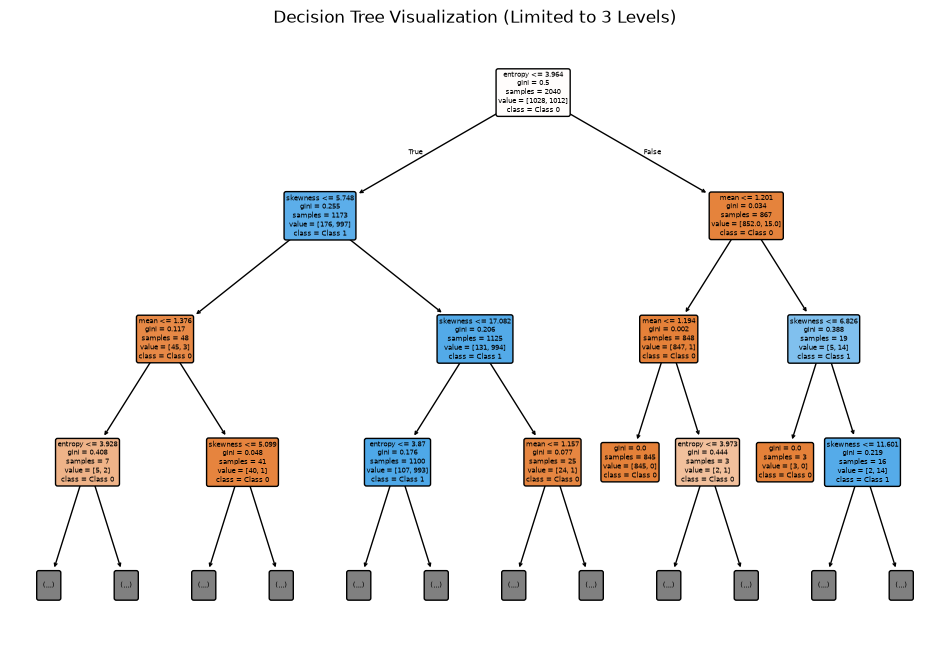

In [8]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import export_text, plot_tree

# Load the trained Decision Tree model from the pickle file
model_dir = 'CFS_selected_features_Set'
tree_model_path = os.path.join(model_dir, 'decision_tree_model_CFS.pkl')

with open(tree_model_path, 'rb') as f:
    decision_tree = pickle.load(f)

# Load the selected features from CSV files (update the input_dir as needed)
input_dir = 'features_after_SelectKBest'
train_data = pd.read_csv(os.path.join(input_dir, "CFS_training_selected_features.csv"))

# Separate features and labels
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

# Define feature names based on your dataset
feature_names = ['skewness', 'mean', 'entropy']  # Update based on your actual features

# Automatically get class names based on unique labels in the dataset
class_names = [f'Class {i}' for i in np.unique(train_labels)]

# --- Method 1: Text-Based Visualization ---
tree_rules = export_text(decision_tree, feature_names=feature_names)
print("\nDecision Tree Rules (Text-Based):")
print(tree_rules)

# --- Method 2: Plotting the Decision Tree (limited to 3 levels) ---
plt.figure(figsize=(12, 8))
plot_tree(decision_tree, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, max_depth=3)
plt.title("Decision Tree Visualization (Limited to 3 Levels)")
plt.show()


Saving decision tree

In [9]:
import pickle
import os

# Directory to save model
model_dir = 'saved_models'
os.makedirs(model_dir, exist_ok=True)

# Save the trained Decision Tree model
tree_model_path = os.path.join(model_dir, 'decision_tree_final_stat_model_with_final_three_features.pkl')
with open(tree_model_path, 'wb') as f:
    pickle.dump(clf, f)

print(f"Decision Tree model saved to: {tree_model_path}")


Decision Tree model saved to: saved_models/decision_tree_final_stat_model_with_final_three_features.pkl


Extracting rules from this tree

In [11]:
import pickle
import numpy as np
import pandas as pd
from sklearn.tree import _tree

# Load the trained decision tree model
model_path = 'saved_models/decision_tree_final_stat_model_with_final_three_features.pkl'
with open(model_path, 'rb') as f:
    clf = pickle.load(f)

# Define feature names (update these based on your selected features)
feature_names = ['skewness', 'mean', 'entropy']  # Update according to your selected features

def tree_to_if_then_statements(tree, feature_names):
    """
    Extracts rules from a decision tree and returns them as a list of "if-then" statements.
    """
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    
    rules = []  # Store all rules as strings

    def recurse(node, rule_str):
        # Recursive function to traverse the decision tree
        if tree_.feature[node] != _tree.TREE_UNDEFINED:  # Non-leaf node
            name = feature_name[node]
            threshold = tree_.threshold[node]
            
            # Left branch
            left_rule = f"{rule_str} if {name} <= {threshold:.3f}:"
            recurse(tree_.children_left[node], left_rule)
            
            # Right branch
            right_rule = f"{rule_str} if {name} > {threshold:.3f}:"
            recurse(tree_.children_right[node], right_rule)
        else:  # Leaf node
            value = tree_.value[node]
            class_label = np.argmax(value)
            rule_str += f" then class = {class_label}  # {value}"
            rules.append(rule_str)  # Add completed rule to the list

    # Start recursion
    recurse(0, "")
    return rules

# Extract rules
rules = tree_to_if_then_statements(clf, feature_names)

# Display the total number of rules
total_rules = len(rules)  # Get the number of rules in the list
print(f"Total Number of Rules: {total_rules}")

# Display rules in the console
print("Decision Tree Rules in 'If-Then' Format:\n")
for rule in rules:
    print(rule)
    


# Save rules to a text file
output_file_path = 'final_decision_tree_3best_features_rules.txt'
with open(output_file_path, 'w') as f:
    for rule in rules:
        f.write(rule + '\n')  # Write each rule on a new line

print(f"\nRules have been saved to {output_file_path}.")


Total Number of Rules: 93
Decision Tree Rules in 'If-Then' Format:

 if entropy <= 3.964: if mean <= 0.930: if mean <= 0.790: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean <= 0.930: if mean > 0.790: if mean <= 0.800: then class = 1  # [[0. 1.]]
 if entropy <= 3.964: if mean <= 0.930: if mean > 0.790: if mean > 0.800: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean <= 3.018: if skewness <= 1.084: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean <= 3.018: if skewness > 1.084: if entropy <= 3.870: if mean <= 2.066: if skewness <= 1.161: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean <= 3.018: if skewness > 1.084: if entropy <= 3.870: if mean <= 2.066: if skewness > 1.161: if mean <= 1.722: if skewness <= 1.581: if skewness <= 1.255: if mean <= 1.511: then class = 0  # [[1. 0.]]
 if entropy <= 3.964: if mean > 0.930: if mean <= 3.018: if skewness > 1.084: if entropy <= 3.870: if mean <= 2.066: if s

Using Rulefit to classify dataset and extract rules

In [13]:
import os
import pandas as pd
import numpy as np
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelBinarizer

# Load the selected features from CSV files after SelectKBest
input_dir = 'features_after_SelectKBest'

train_data = pd.read_csv(os.path.join(input_dir, "CFS_training_selected_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "CFS_testing_selected_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "CFS_validation_selected_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Define feature names based on your dataset
feature_names = ['skewness', 'mean', 'entropy']  # Update based on your actual features

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels, feature_names=feature_names)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding or using a threshold
# Since it's multiclass, we can round to the nearest integer or use argmax if using probabilities
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Save rules to a text file
output_file_path = 'rulefit_rules_with_final_3_Statistical_features.txt'
rules.to_csv(output_file_path, index=False)
print(f"Rules have been saved to {output_file_path}.")


Combined Training + Validation Features Shape: (2040, 3)
Combined Training + Validation Labels Shape: (2040,)


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.505649e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.696416e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning

Testing Accuracy: 0.9528
Confusion Matrix:
[[156  16]
 [  1 187]]
Top Rules from RuleFit Model:
                                                   rule  type      coef  \
423   entropy <= 3.9561487436294556 & skewness > 1.0...  rule  0.231691   
1734  mean > 0.9332385063171387 & entropy <= 3.96308...  rule  0.221813   
75    mean <= 2.8926905393600464 & entropy > 3.87582...  rule  0.110782   
673   skewness <= 1.593386709690094 & mean > 0.92332...  rule  0.203918   
701   entropy > 3.95705509185791 & skewness <= 1.308...  rule -0.070991   

       support  importance  
423   0.459459    0.115464  
1734  0.548649    0.110380  
75    0.527027    0.055310  
673   0.970270    0.034634  
701   0.378378    0.034429  
Rules have been saved to rulefit_rules_with_final_3_Statistical_features.txt.


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.517301e-01, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


Combined Training + Validation Features Shape: (2040, 3)
Combined Training + Validation Labels Shape: (2040,)


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.505649e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.696416e-02, tolerance: 3.400e-02
  model = cd_fast.enet_coordinate_descent(
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning

Testing Accuracy: 0.9528
Confusion Matrix:
[[156  16]
 [  1 187]]
Top Rules from RuleFit Model:
                                                   rule  type      coef  \
423   entropy <= 3.9561487436294556 & skewness > 1.0...  rule  0.231691   
1734  mean > 0.9332385063171387 & entropy <= 3.96308...  rule  0.221813   
75    mean <= 2.8926905393600464 & entropy > 3.87582...  rule  0.110782   
673   skewness <= 1.593386709690094 & mean > 0.92332...  rule  0.203918   
701   entropy > 3.95705509185791 & skewness <= 1.308...  rule -0.070991   

       support  importance  
423   0.459459    0.115464  
1734  0.548649    0.110380  
75    0.527027    0.055310  
673   0.970270    0.034634  
701   0.378378    0.034429  


/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.517301e-01, tolerance: 5.100e-02
  model = cd_fast.enet_coordinate_descent(


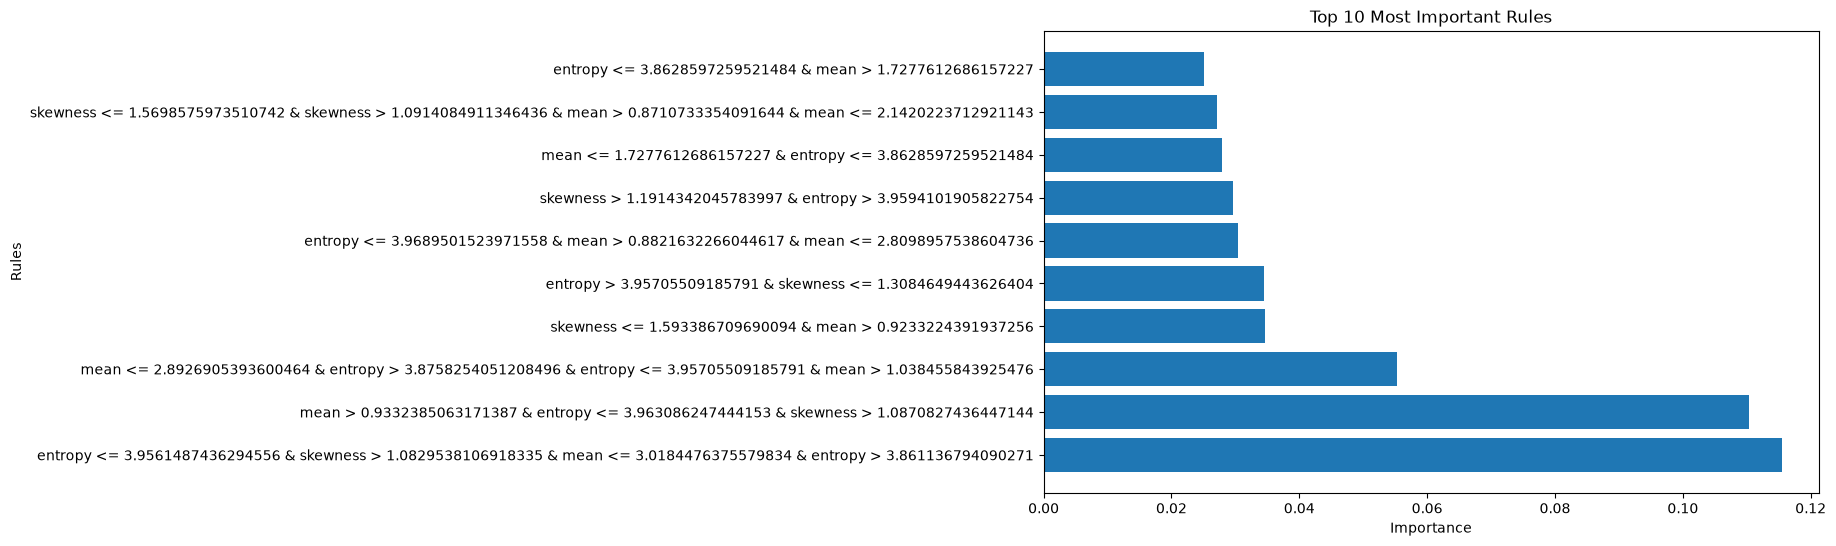

Rules have been saved to rulefit_rules.txt.


In [15]:
import os
import pandas as pd
import numpy as np
from rulefit import RuleFit
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import export_text
import matplotlib.pyplot as plt

# Load the selected features from CSV files
input_dir = 'features_after_SelectKBest'

train_data = pd.read_csv(os.path.join(input_dir, "CFS_training_selected_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "CFS_testing_selected_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "CFS_validation_selected_features.csv"))

# Separate features and labels for each dataset
train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

# Combine training and validation data for final training
train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(f"Combined Training + Validation Features Shape: {train_val_features.shape}")
print(f"Combined Training + Validation Labels Shape: {train_val_labels.shape}")

# Define feature names based on your dataset
feature_names = ['skewness', 'mean', 'entropy']  # Update based on your actual features

# Initialize RuleFit model
rf = RuleFit(tree_size=3, sample_fract=1.0, max_rules=2000, random_state=42)

# Fit the RuleFit model to combined training and validation data
rf.fit(train_val_features, train_val_labels, feature_names=feature_names)

# Predict on the test set (continuous values)
test_predictions = rf.predict(test_features)

# Convert continuous predictions to discrete class labels by rounding
test_predictions_discrete = np.round(test_predictions).astype(int)

# Ensure the predicted labels are within the valid range of classes
test_predictions_discrete = np.clip(test_predictions_discrete, np.min(train_val_labels), np.max(train_val_labels))

# Calculate testing accuracy
test_accuracy = accuracy_score(test_labels, test_predictions_discrete)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_discrete)
print("Confusion Matrix:")
print(conf_matrix)

# Extract rules from the RuleFit model
rules = rf.get_rules()
rules = rules[rules.coef != 0].sort_values("importance", ascending=False)

# Display the top rules
print("Top Rules from RuleFit Model:")
print(rules.head())

# Visualizing Rule Importance as a Bar Chart
plt.figure(figsize=(10, 6))
plt.barh(rules['rule'][:10], rules['importance'][:10])
plt.xlabel('Importance')
plt.ylabel('Rules')
plt.title('Top 10 Most Important Rules')
plt.show()

# Save rules to a text file for reference
output_file_path = 'rulefit_rules.txt'
rules.to_csv(output_file_path, index=False)
print(f"Rules have been saved to {output_file_path}.")


In [16]:
# Display the total number of rules
total_rules = rules.shape[0]  # Number of rows in the DataFrame
print(f"Total Number of Rules: {total_rules}")

Total Number of Rules: 86


In [2]:
import os
import pandas as pd
import numpy as np

input_dir = 'features_after_SelectKBest'

train_data = pd.read_csv(os.path.join(input_dir, "CFS_training_selected_features.csv"))
val_data = pd.read_csv(os.path.join(input_dir, "CFS_validation_selected_features.csv"))
test_data = pd.read_csv(os.path.join(input_dir, "CFS_testing_selected_features.csv"))

train_features = train_data.drop(columns=['label']).values
train_labels = train_data['label'].values

val_features = val_data.drop(columns=['label']).values
val_labels = val_data['label'].values

test_features = test_data.drop(columns=['label']).values
test_labels = test_data['label'].values

train_val_features = np.vstack([train_features, val_features])
train_val_labels = np.hstack([train_labels, val_labels])

print(train_val_features.shape)

(2040, 3)


Explainable Boosting Machines (EBMs)

In [3]:
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Initialize the EBM classifier
ebm = ExplainableBoostingClassifier(random_state=42)

# Train on the combined training and validation data
ebm.fit(train_val_features, train_val_labels)

# Predict on the test set
test_predictions = ebm.predict(test_features)

# Calculate accuracy
test_accuracy = accuracy_score(test_labels, test_predictions)
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Generate confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions)
print("Confusion Matrix:")
print(conf_matrix)

# Extract and display EBM model insights
global_explanation = ebm.explain_global()
print(global_explanation.data())


Testing Accuracy: 0.9556
Confusion Matrix:
[[157  15]
 [  1 187]]
{'type': 'univariate', 'names': ['feature_0000', 'feature_0001', 'feature_0002', 'feature_0000 & feature_0001', 'feature_0000 & feature_0002', 'feature_0001 & feature_0002'], 'scores': [np.float64(3.1632557860402004), np.float64(1.5099536411033432), np.float64(2.637218911319959), np.float64(0.25130361318706745), np.float64(1.3497936383406413), np.float64(0.570766688718495)]}


Association Rule Mining (using Apriori algorithm) creation from my final selected features without median 

In [2]:
import os
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
import pandas as pd

## Load the selected statistical features and labels
selected_stat_feature_dir = 'features_after_SelectKBest'
train_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_training_selected_features.csv"))
val_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_testing_selected_features.csv"))
test_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_validation_selected_features.csv"))



# Step 2: Prepare the data by concatenating all datasets for consistent thresholding
combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Step 3: Binarize the features based on mean threshold
thresholds = combined_df.mean()

# Create binary features based on whether they are above or below the mean
for feature in thresholds.index[:-1]:  # Exclude the 'label' column
    combined_df[feature] = combined_df[feature] > thresholds[feature]

# Split the data back into training, validation, and testing sets after binarization
train_bin = combined_df.iloc[:len(train_df)]
val_bin = combined_df.iloc[len(train_df):len(train_df) + len(val_df)]
test_bin = combined_df.iloc[len(train_df) + len(val_df):]

# Step 4: Generate frequent itemsets using the binarized training set (excluding the 'label' column)
frequent_itemsets = apriori(train_bin.drop(columns=['label']), min_support=0.1, use_colnames=True)

# Step 5: Extract association rules from the frequent itemsets based on confidence
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

# Display the generated association rules
print("Association Rules:")
print(rules)

# Step 6: Optionally save the association rules to a CSV file
rules.to_csv('association_rules.csv', index=False)

# Evaluate the rules: For example, display the top 5 association rules based on lift
top_rules = rules.sort_values(by='lift', ascending=False).head(5)
print("Top 5 Association Rules based on lift:")
print(top_rules)


Association Rules:
            antecedents           consequents  antecedent support  \
0  frozenset({entropy})     frozenset({mean})            0.419643   
1     frozenset({mean})  frozenset({entropy})            0.477381   

   consequent support   support  confidence     lift  representativity  \
0            0.477381  0.294048    0.700709  1.46782               1.0   
1            0.419643  0.294048    0.615960  1.46782               1.0   

   leverage  conviction  zhangs_metric  jaccard  certainty  kulczynski  
0  0.093718    1.746192       0.549175  0.48766   0.427325    0.658335  
1  0.093718    1.511190       0.609847  0.48766   0.338270    0.658335  
Top 5 Association Rules based on lift:
            antecedents           consequents  antecedent support  \
0  frozenset({entropy})     frozenset({mean})            0.419643   
1     frozenset({mean})  frozenset({entropy})            0.477381   

   consequent support   support  confidence     lift  representativity  \
0         

Association rules on final feature set with accuracy of 85%

In [4]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
import os

## Load the selected statistical features and labels
selected_stat_feature_dir = 'features_after_SelectKBest'
train_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_training_selected_features.csv"))
val_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_testing_selected_features.csv"))
test_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "CFS_validation_selected_features.csv"))

# Step 2: Prepare the data by concatenating all datasets for consistent thresholding
combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Step 3: Binarize the features based on mean threshold
thresholds = combined_df.mean()

# Create binary features based on whether they are above or below the mean
for feature in thresholds.index[:-1]:  # Exclude the 'label' column
    combined_df[feature] = combined_df[feature] > thresholds[feature]

# Handle NaN values by filling them with False (or 0)
combined_df.fillna(False, inplace=True)  # Fill NaNs with False for binary features

# Split the data back into training, validation, and testing sets after binarization
train_bin = combined_df.iloc[:len(train_df)]
val_bin = combined_df.iloc[len(train_df):len(train_df) + len(val_df)]
test_bin = combined_df.iloc[len(train_df) + len(val_df):]

# Step 4: Generate frequent itemsets using the binarized training set (excluding the 'label' column)
frequent_itemsets = apriori(train_bin.drop(columns=['label']), min_support=0.05, use_colnames=True)

# Step 5: Extract association rules from the frequent itemsets based on confidence
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.1)

# Function to display rules in IF-THEN format
def display_rules_in_if_then_format(rules_df):
    for index, row in rules_df.iterrows():
        antecedents = list(row['antecedents'])
        consequents = list(row['consequents'])
        antecedent_str = " AND ".join([str(antecedent) + " = True" for antecedent in antecedents])
        consequent_str = " AND ".join([str(consequent) + " = True" for consequent in consequents])
        
        print(f"IF {antecedent_str} THEN {consequent_str} "
              f"(support: {row['support']:.2f}, confidence: {row['confidence']:.2f}, lift: {row['lift']:.2f})")

# Display the association rules in the form of IF-THEN
print("Association Rules in IF-THEN format:")
display_rules_in_if_then_format(rules)

# Optionally save the association rules in IF-THEN format to a text file
with open('if_then_association_rules.txt', 'w') as f:
    for index, row in rules.iterrows():
        antecedents = list(row['antecedents'])
        consequents = list(row['consequents'])
        antecedent_str = " AND ".join([str(antecedent) + " = True" for antecedent in antecedents])
        consequent_str = " AND ".join([str(consequent) + " = True" for consequent in consequents])
        
        rule_text = (f"IF {antecedent_str} THEN {consequent_str} "
                     f"(support: {row['support']:.2f}, confidence: {row['confidence']:.2f}, lift: {row['lift']:.2f})\n")
        f.write(rule_text)

# Step 6: Optionally save the original association rules to a CSV file
rules.to_csv('association_rules.csv', index=False)

# Evaluate the rules: For example, display the top 5 association rules based on lift
top_rules = rules.sort_values(by='lift', ascending=False).head(5)
print("\nTop 5 Association Rules based on lift in IF-THEN format:")
display_rules_in_if_then_format(top_rules)


Association Rules in IF-THEN format:
IF skewness = True THEN mean = True (support: 0.22, confidence: 0.36, lift: 0.76)
IF mean = True THEN skewness = True (support: 0.22, confidence: 0.47, lift: 0.76)
IF entropy = True THEN mean = True (support: 0.29, confidence: 0.70, lift: 1.47)
IF mean = True THEN entropy = True (support: 0.29, confidence: 0.62, lift: 1.47)

Top 5 Association Rules based on lift in IF-THEN format:
IF entropy = True THEN mean = True (support: 0.29, confidence: 0.70, lift: 1.47)
IF mean = True THEN entropy = True (support: 0.29, confidence: 0.62, lift: 1.47)
IF skewness = True THEN mean = True (support: 0.22, confidence: 0.36, lift: 0.76)
IF mean = True THEN skewness = True (support: 0.22, confidence: 0.47, lift: 0.76)


Generation of rules extracted using Apriori algorithm in the form of if then

In [6]:
import os
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# Define the output directory where the CFS-selected features are saved
selected_stat_feature_dir = 'selected_statistical_features_without_median'

# Load the selected features from CSV files after CFS
train_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
test_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))
val_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))


# Step 2: Prepare the data by concatenating all datasets for consistent thresholding
combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Step 3: Binarize the features based on mean threshold
thresholds = combined_df.mean()

# Create binary features based on whether they are above or below the mean
for feature in thresholds.index[:-1]:  # Exclude the 'label' column
    combined_df[feature] = combined_df[feature] > thresholds[feature]

# Split the data back into training, validation, and testing sets after binarization
train_bin = combined_df.iloc[:len(train_df)]
val_bin = combined_df.iloc[len(train_df):len(train_df) + len(val_df)]
test_bin = combined_df.iloc[len(train_df) + len(val_df):]

# Step 4: Generate frequent itemsets using the binarized training set (excluding the 'label' column)
frequent_itemsets = apriori(train_bin.drop(columns=['label']), min_support=0.1, use_colnames=True)

# Step 5: Extract association rules from the frequent itemsets based on confidence
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

# Function to display rules in IF-THEN format
def display_rules_in_if_then_format(rules_df):
    for index, row in rules_df.iterrows():
        antecedents = list(row['antecedents'])
        consequents = list(row['consequents'])
        antecedent_str = " AND ".join([str(antecedent) + " = True" for antecedent in antecedents])
        consequent_str = " AND ".join([str(consequent) + " = True" for consequent in consequents])
        
        print(f"IF {antecedent_str} THEN {consequent_str} "
              f"(support: {row['support']:.2f}, confidence: {row['confidence']:.2f}, lift: {row['lift']:.2f})")

# Display the association rules in the form of IF-THEN
print("Association Rules in IF-THEN format:")
display_rules_in_if_then_format(rules)

# Optionally save the association rules in IF-THEN format to a text file
with open('if_then_association_rules.txt', 'w') as f:
    for index, row in rules.iterrows():
        antecedents = list(row['antecedents'])
        consequents = list(row['consequents'])
        antecedent_str = " AND ".join([str(antecedent) + " = True" for antecedent in antecedents])
        consequent_str = " AND ".join([str(consequent) + " = True" for consequent in consequents])
        
        rule_text = (f"IF {antecedent_str} THEN {consequent_str} "
                     f"(support: {row['support']:.2f}, confidence: {row['confidence']:.2f}, lift: {row['lift']:.2f})\n")
        f.write(rule_text)

# Step 6: Optionally save the original association rules to a CSV file
rules.to_csv('association_rules.csv', index=False)

# Evaluate the rules: For example, display the top 5 association rules based on lift
top_rules = rules.sort_values(by='lift', ascending=False).head(5)
print("\nTop 5 Association Rules based on lift in IF-THEN format:")
display_rules_in_if_then_format(top_rules)


Association Rules in IF-THEN format:
IF mean_abs_dev = True THEN skewness = True (support: 0.26, confidence: 0.54, lift: 0.87)
IF skewness = True THEN range = True (support: 0.33, confidence: 0.54, lift: 1.12)
IF range = True THEN skewness = True (support: 0.33, confidence: 0.69, lift: 1.12)
IF mean = True THEN mean_abs_dev = True (support: 0.44, confidence: 0.92, lift: 1.95)
IF mean_abs_dev = True THEN mean = True (support: 0.44, confidence: 0.93, lift: 1.95)
IF entropy = True THEN mean_abs_dev = True (support: 0.26, confidence: 0.61, lift: 1.29)
IF mean_abs_dev = True THEN entropy = True (support: 0.26, confidence: 0.54, lift: 1.29)
IF mean_abs_dev = True THEN range = True (support: 0.40, confidence: 0.85, lift: 1.76)
IF range = True THEN mean_abs_dev = True (support: 0.40, confidence: 0.83, lift: 1.76)
IF entropy = True THEN mean = True (support: 0.29, confidence: 0.70, lift: 1.47)
IF mean = True THEN entropy = True (support: 0.29, confidence: 0.62, lift: 1.47)
IF mean = True THEN r

Code for Visualizing feature importance

/var/folders/wf/r_mmzcb55yn6yfsx8xb71w540000gn/T/ipykernel_71430/2605981103.py:40: RuntimeWarning: invalid value encountered in divide
  normalized_matrix = occurrence_matrix / np.max(occurrence_matrix)
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/Users/kaivalyapuranik/Desktop/XAI-Med-Images-Stat-Visual-Rules/.venv-new/lib/python3.13/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


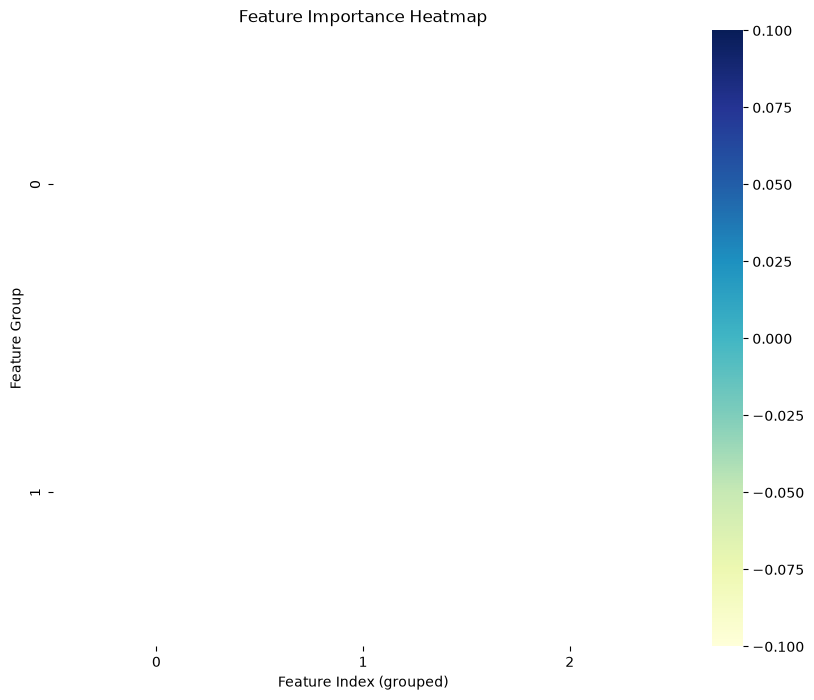

In [7]:
import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Function to read the rules from file and extract antecedents
def extract_antecedents(filename):
    with open(filename, 'r') as file:
        rules = file.readlines()
    
    antecedents = []
    
    # Regex pattern to capture the antecedents from the rules
    antecedent_pattern = re.compile(r'IF\s(.+)\sTHEN')
    
    # Iterate over each rule to extract antecedents
    for rule in rules:
        match = antecedent_pattern.search(rule)
        if match:
            antecedent = match.group(1)
            antecedents.append(antecedent)
    
    return antecedents

# Function to create the occurrence matrix
def create_occurrence_matrix(antecedents, num_features):
    occurrence_matrix = np.zeros(num_features)
    
    # Regex pattern to capture the feature indices from the antecedents
    feature_pattern = re.compile(r'X(\d+)\s*')

    # Iterate over antecedents to count feature occurrences
    for antecedent in antecedents:
        features = feature_pattern.findall(antecedent)
        for feature in features:
            feature_index = int(feature)  # Convert feature index from string to int
            occurrence_matrix[feature_index] += 1
    
    # Normalize the occurrence matrix (between 0 and 1)
    normalized_matrix = occurrence_matrix / np.max(occurrence_matrix)
    
    return normalized_matrix

# Function to visualize the matrix as a heatmap
def visualize_occurrences(occurrence_matrix, num_features):
    # Reshape the matrix for better visualization (e.g., grouping features into a 2D matrix)
    matrix_reshaped = occurrence_matrix.reshape((int(np.sqrt(num_features)), -1))
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(matrix_reshaped, cmap="YlGnBu", annot=False)
    plt.title('Feature Importance Heatmap')
    plt.xlabel('Feature Index (grouped)')
    plt.ylabel('Feature Group')
    plt.show()

# Main workflow
if __name__ == "__main__":
    # Assuming you have 168 features (adapt based on your number of features)
    num_features = 6  # Adjust to match the number of features from your dataset
    
    # Step 1: Extract antecedents from the rules file
    antecedents = extract_antecedents('if_then_association_rules.txt')
    
    # Step 2: Create the occurrence matrix
    occurrence_matrix = create_occurrence_matrix(antecedents, num_features)
    
    # Step 3: Visualize the occurrences as a heatmap
    visualize_occurrences(occurrence_matrix, num_features)


All Rules visualization

                   antecedents                  consequents  \
0  frozenset({'mean_abs_dev'})      frozenset({'skewness'})   
1      frozenset({'skewness'})         frozenset({'range'})   
2         frozenset({'range'})      frozenset({'skewness'})   
3          frozenset({'mean'})  frozenset({'mean_abs_dev'})   
4  frozenset({'mean_abs_dev'})          frozenset({'mean'})   

   antecedent support  consequent support   support  confidence      lift  \
0            0.474405            0.616667  0.255357    0.538269  0.872868   
1            0.616667            0.483929  0.334524    0.542471  1.120973   
2            0.483929            0.616667  0.334524    0.691267  1.120973   
3            0.477381            0.474405  0.441071    0.923940  1.947578   
4            0.474405            0.477381  0.441071    0.929737  1.947578   

   representativity  leverage  conviction  zhangs_metric   jaccard  certainty  \
0               1.0 -0.037192    0.830208      -0.216983  0.305556  -0.204517

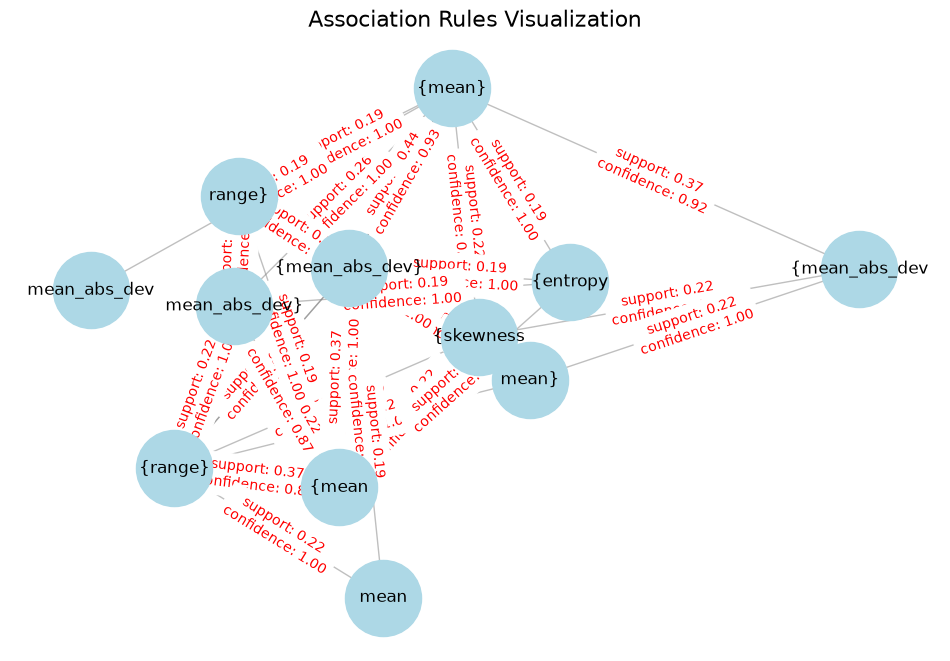

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Load the association rules from CSV
df_rules = pd.read_csv('association_rules.csv')

# Display the first few rows of the DataFrame
print(df_rules.head())

# Filter rules based on high confidence
high_confidence_rules = df_rules[df_rules['confidence'] > 0.8]

# Create a directed graph from the rules
G = nx.DiGraph()

# Add edges for the antecedents and consequents
for index, row in high_confidence_rules.iterrows():
    antecedents = list(row['antecedents'].strip("frozenset()").split(","))
    consequents = list(row['consequents'].strip("frozenset()").split(","))
    
    # Create edges for each antecedent to its consequent
    for antecedent in antecedents:
        for consequent in consequents:
            G.add_edge(antecedent.strip().replace("'", ""), consequent.strip().replace("'", ""), 
                       weight=row['support'], confidence=row['confidence'])

# Set node positions using a layout
pos = nx.spring_layout(G, seed=42)

# Draw the nodes and edges
plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(G, pos, node_size=3000, node_color='lightblue')
nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=20, edge_color='gray', alpha=0.5)

# Draw labels
labels = {node: node for node in G.nodes()}
nx.draw_networkx_labels(G, pos, labels, font_size=12)

# Add edge labels for support and confidence
edge_labels = {(u, v): f'support: {d["weight"]:.2f}\nconfidence: {d["confidence"]:.2f}' 
               for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

# Set plot title and show the graph
plt.title('Association Rules Visualization', fontsize=16)
plt.axis('off')  # Hide axes
plt.show()


top rules using threshold

In [2]:
import re

# Function to read the rules from file and filter based on support and confidence
def filter_association_rules(filename, support_threshold, confidence_threshold):
    with open(filename, 'r') as file:
        rules = file.readlines()

    filtered_rules = []
    
    # Regex pattern to capture support and confidence values from the rules
    pattern = re.compile(r'support: ([0-9.]+), confidence: ([0-9.]+)')
    
    # Iterate over each rule
    for rule in rules:
        # Search for the support and confidence values using regex
        match = pattern.search(rule)
        if match:
            support = float(match.group(1))
            confidence = float(match.group(2))
            
            # Apply the thresholds for filtering
            if support >= support_threshold and confidence >= confidence_threshold:
                filtered_rules.append(rule.strip())

    return filtered_rules

# Set your threshold values for support and confidence
support_threshold = 0.15  # You can adjust this value
confidence_threshold = 0.5 # You can adjust this value

# Read and filter the rules from the file
filtered_rules = filter_association_rules('if_then_association_rules.txt', support_threshold, confidence_threshold)

# Print the filtered rules
print(f"Total rules after filtering: {len(filtered_rules)}\n")
for rule in filtered_rules:
    print(rule)


Total rules after filtering: 59

IF mean_abs_dev = True THEN skewness = True (support: 0.26, confidence: 0.54, lift: 0.87)
IF skewness = True THEN range = True (support: 0.33, confidence: 0.54, lift: 1.12)
IF range = True THEN skewness = True (support: 0.33, confidence: 0.69, lift: 1.12)
IF mean = True THEN mean_abs_dev = True (support: 0.44, confidence: 0.92, lift: 1.95)
IF mean_abs_dev = True THEN mean = True (support: 0.44, confidence: 0.93, lift: 1.95)
IF entropy = True THEN mean_abs_dev = True (support: 0.26, confidence: 0.61, lift: 1.29)
IF mean_abs_dev = True THEN entropy = True (support: 0.26, confidence: 0.54, lift: 1.29)
IF mean_abs_dev = True THEN range = True (support: 0.40, confidence: 0.85, lift: 1.76)
IF range = True THEN mean_abs_dev = True (support: 0.40, confidence: 0.83, lift: 1.76)
IF entropy = True THEN mean = True (support: 0.29, confidence: 0.70, lift: 1.47)
IF mean = True THEN entropy = True (support: 0.29, confidence: 0.62, lift: 1.47)
IF mean = True THEN range

Rules Visualization Code

Total rules after filtering: 46

IF mean_abs_dev = True THEN skewness = True (support: 0.26, confidence: 0.54, lift: 0.87)
IF skewness = True THEN range = True (support: 0.33, confidence: 0.54, lift: 1.12)
IF range = True THEN skewness = True (support: 0.33, confidence: 0.69, lift: 1.12)
IF mean = True THEN mean_abs_dev = True (support: 0.44, confidence: 0.92, lift: 1.95)
IF mean_abs_dev = True THEN mean = True (support: 0.44, confidence: 0.93, lift: 1.95)
IF entropy = True THEN mean_abs_dev = True (support: 0.26, confidence: 0.61, lift: 1.29)
IF mean_abs_dev = True THEN entropy = True (support: 0.26, confidence: 0.54, lift: 1.29)
IF mean_abs_dev = True THEN range = True (support: 0.40, confidence: 0.85, lift: 1.76)
IF range = True THEN mean_abs_dev = True (support: 0.40, confidence: 0.83, lift: 1.76)
IF entropy = True THEN mean = True (support: 0.29, confidence: 0.70, lift: 1.47)
IF mean = True THEN entropy = True (support: 0.29, confidence: 0.62, lift: 1.47)
IF mean = True THEN range

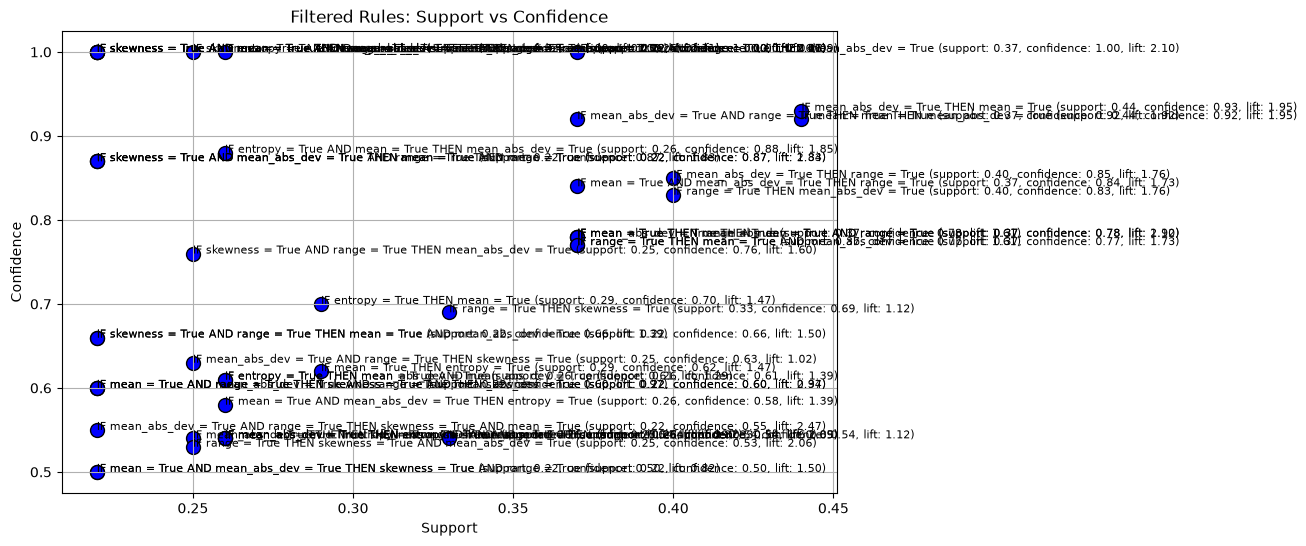

In [3]:
import re
import matplotlib.pyplot as plt

# Function to read the rules from file and filter based on support and confidence
def filter_association_rules(filename, support_threshold, confidence_threshold):
    with open(filename, 'r') as file:
        rules = file.readlines()

    filtered_rules = []
    
    # Regex pattern to capture support and confidence values from the rules
    pattern = re.compile(r'support: ([0-9.]+), confidence: ([0-9.]+)')
    
    # Iterate over each rule
    for rule in rules:
        # Search for the support and confidence values using regex
        match = pattern.search(rule)
        if match:
            support = float(match.group(1))
            confidence = float(match.group(2))
            
            # Apply the thresholds for filtering
            if support >= support_threshold and confidence >= confidence_threshold:
                filtered_rules.append(rule.strip())

    return filtered_rules

# Function to visualize the filtered rules
def visualize_rules(rules):
    supports = []
    confidences = []
    rule_texts = []

    # Extract support, confidence, and rule text for visualization
    pattern = re.compile(r'support: ([0-9.]+), confidence: ([0-9.]+)')
    for rule in rules:
        match = pattern.search(rule)
        if match:
            supports.append(float(match.group(1)))
            confidences.append(float(match.group(2)))
            rule_texts.append(rule.split("=>")[0].strip())  # Use the antecedent part of the rule for visualization
    
    # Plot the filtered rules
    plt.figure(figsize=(10, 6))
    plt.scatter(supports, confidences, c='blue', marker='o', s=100, edgecolor='k')
    plt.title('Filtered Rules: Support vs Confidence')
    plt.xlabel('Support')
    plt.ylabel('Confidence')

    # Annotate points with rule antecedents
    for i, rule_text in enumerate(rule_texts):
        plt.annotate(rule_text, (supports[i], confidences[i]), fontsize=8)

    plt.grid(True)
    plt.show()

# Set your threshold values for support and confidence
support_threshold = 0.2  # You can adjust this value
confidence_threshold = 0.5  # You can adjust this value

# Read and filter the rules from the file
filtered_rules = filter_association_rules('if_then_association_rules.txt', support_threshold, confidence_threshold)

# Print the filtered rules
print(f"Total rules after filtering: {len(filtered_rules)}\n")
for rule in filtered_rules:
    print(rule)

# Visualize only the filtered rules
if filtered_rules:
    visualize_rules(filtered_rules)
else:
    print("No rules met the threshold criteria for support and confidence.")


Calculate Feature Importance from Association Rules

In [4]:
import pandas as pd
import numpy as np

# Load the association rules from CSV
df_rules = pd.read_csv('association_rules.csv')

# Initialize a dictionary to hold feature importance scores
feature_importance = {}

# Calculate importance based on support and confidence
for index, row in df_rules.iterrows():
    # Clean and split antecedents
    antecedents = row['antecedents'].strip("frozenset()").split(",")
    support = row['support']
    confidence = row['confidence']
    
    for feature in antecedents:
        # Additional cleaning for feature names
        feature = feature.strip().replace("'", "").replace("{", "").replace("}", "")
        if feature not in feature_importance:
            feature_importance[feature] = 0
        # Update importance score
        feature_importance[feature] += support * confidence

# Convert the dictionary to a DataFrame for easier visualization
df_feature_importance = pd.DataFrame(list(feature_importance.items()), columns=['Feature', 'Importance'])
df_feature_importance = df_feature_importance.sort_values(by='Importance', ascending=False)

print("Feature Importance based on Association Rules:")
print(df_feature_importance)


Feature Importance based on Association Rules:
        Feature  Importance
0  mean_abs_dev    5.041329
3          mean    4.940362
2         range    4.784447
1      skewness    2.612278
4       entropy    2.591693


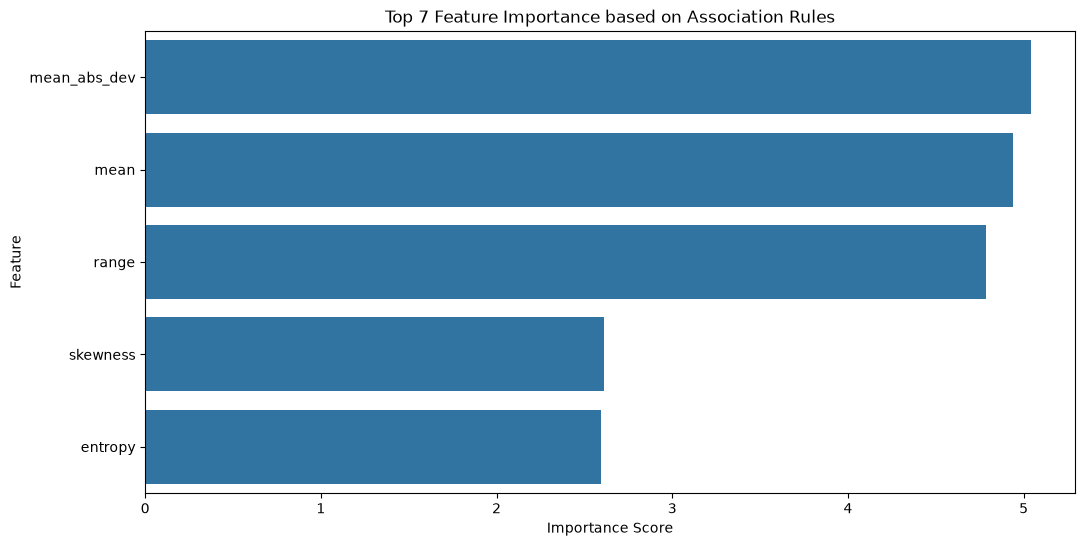

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(data=df_feature_importance.head(7), x='Importance', y='Feature')
plt.title('Top 7 Feature Importance based on Association Rules')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()


In [7]:
print(train_df.columns.tolist())

['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range', 'label']


Using only these five features for classification of tree

In [8]:
import pandas as pd
import os

# Load the selected statistical features and labels
selected_stat_feature_dir = 'selected_statistical_features_without_median'
train_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Define the important features to keep
important_features = ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range']
      

# Filter the DataFrames to keep only the important features and the labels
# Assuming your labels are in a column named 'label'
# Change 'label' to the actual name of your label column if it's different
train_df_filtered = train_df[important_features + ['label']]
val_df_filtered = val_df[important_features + ['label']]
test_df_filtered = test_df[important_features + ['label']]

# Create a new directory to save the final statistical features if it doesn't exist
final_feature_dir = 'final_statistical_features_after_AR'
os.makedirs(final_feature_dir, exist_ok=True)

# Save the filtered DataFrames to new CSV files
train_df_filtered.to_csv(os.path.join(final_feature_dir, "AR_selected_training_statistical_features.csv"), index=False)
val_df_filtered.to_csv(os.path.join(final_feature_dir, "AR_selected_validation_statistical_features.csv"), index=False)
test_df_filtered.to_csv(os.path.join(final_feature_dir, "AR_selected_testing_statistical_features.csv"), index=False)

print("Filtered files have been saved successfully.")


Filtered files have been saved successfully.


Decision tree for classification

Combined Training Accuracy: 1.0000
Testing Accuracy: 0.9472


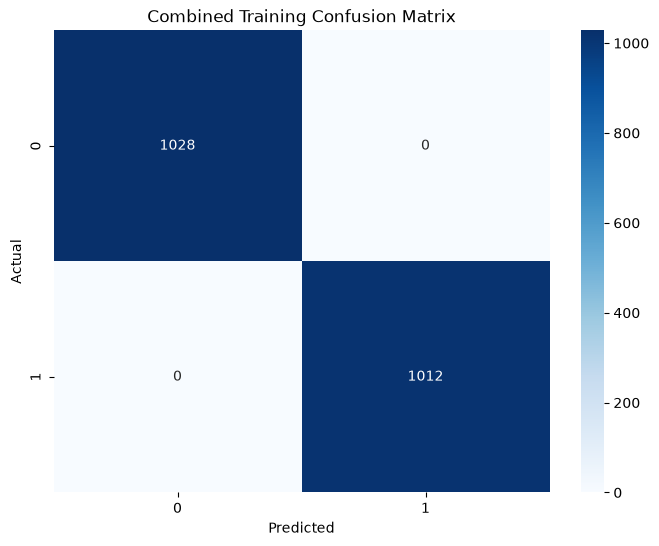

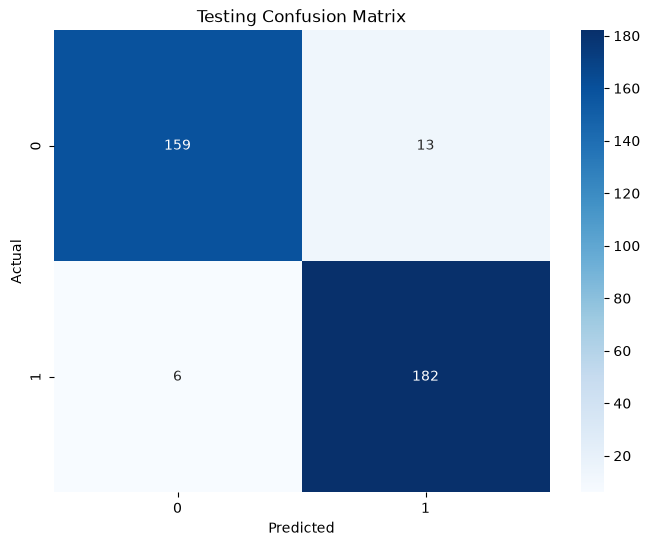


Classification Report for Combined Training Data:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1028
           1       1.00      1.00      1.00      1012

    accuracy                           1.00      2040
   macro avg       1.00      1.00      1.00      2040
weighted avg       1.00      1.00      1.00      2040


Classification Report for Testing Data:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       172
           1       0.93      0.97      0.95       188

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



In [9]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Load the final statistical features and labels
final_feature_dir = 'final_statistical_features_after_AR'
train_df = pd.read_csv(os.path.join(final_feature_dir, "AR_selected_training_statistical_features.csv"))
val_df = pd.read_csv(os.path.join(final_feature_dir, "AR_selected_validation_statistical_features.csv"))
test_df = pd.read_csv(os.path.join(final_feature_dir, "AR_selected_testing_statistical_features.csv"))

# Separate features and labels
X_train = train_df.drop(columns=['label'])  # Assuming the label column is named 'label'
y_train = train_df['label']

X_val = val_df.drop(columns=['label'])
y_val = val_df['label']

X_test = test_df.drop(columns=['label'])
y_test = test_df['label']

# Combine training and validation datasets
X_combined_train = pd.concat([X_train, X_val], axis=0)
y_combined_train = pd.concat([y_train, y_val], axis=0)

# Initialize and train the Decision Tree Classifier on the combined data
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_combined_train, y_combined_train)

# Predictions on the combined training data and test data
y_combined_train_pred = dt_classifier.predict(X_combined_train)
y_test_pred = dt_classifier.predict(X_test)

# Calculate accuracy
combined_train_accuracy = accuracy_score(y_combined_train, y_combined_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Combined Training Accuracy: {combined_train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

# Confusion Matrices
def plot_confusion_matrix(cm, labels, title='Confusion Matrix'):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Compute and plot confusion matrices
combined_train_cm = confusion_matrix(y_combined_train, y_combined_train_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

labels = sorted(y_combined_train.unique())  # Adjust labels according to your dataset

plot_confusion_matrix(combined_train_cm, labels, title='Combined Training Confusion Matrix')
plot_confusion_matrix(test_cm, labels, title='Testing Confusion Matrix')

# Optional: Classification report
print("\nClassification Report for Combined Training Data:")
print(classification_report(y_combined_train, y_combined_train_pred))

print("\nClassification Report for Testing Data:")
print(classification_report(y_test, y_test_pred))


Genetic Algorithm for Association Rules Extraction (Using DEAP)

In [1]:
import pandas as pd
import os
import random
import numpy as np
from deap import base, creator, tools, algorithms

# Load the selected statistical features and labels
selected_stat_feature_dir = 'selected_statistical_features_without_median'
train_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_training_statistical_features.csv"))
val_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_validation_statistical_features.csv"))
test_df = pd.read_csv(os.path.join(selected_stat_feature_dir, "selected_testing_statistical_features.csv"))

# Concatenate datasets
combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Binarize the features based on mean threshold
thresholds = combined_df.mean()
for feature in thresholds.index[:-1]:
    combined_df[feature] = combined_df[feature] > thresholds[feature]

# Split the data back into training, validation, and testing sets after binarization
train_bin = combined_df.iloc[:len(train_df)]
val_bin = combined_df.iloc[len(train_df):len(train_df) + len(val_df)]
test_bin = combined_df.iloc[len(train_df) + len(val_df):]

# Define evaluation function for fitness (support, confidence, lift)
def evaluate(individual):
    selected_features = [i for i, bit in enumerate(individual) if bit == 1]
    
    if not selected_features:
        return 0, 0, 0  # Return 0 if no features are selected
    
    # Create a new DataFrame with selected features
    subset_train = train_bin.iloc[:, selected_features]
    
    # Calculate support (percentage of rows that meet the condition)
    support = subset_train.sum(axis=1).mean()
    
    # For simplicity, assume confidence and lift calculations (mocked values here)
    confidence = random.uniform(0.5, 1)
    lift = random.uniform(1, 2)
    
    return support, confidence, lift

# Genetic algorithm setup
creator.create("FitnessMulti", base.Fitness, weights=(1.0, 1.0, 1.0))  # Maximizing support, confidence, and lift
creator.create("Individual", list, fitness=creator.FitnessMulti)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)  # Binary representation (0 or 1 for each feature)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=len(train_bin.columns) - 1)  # -1 to exclude the 'label'
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
toolbox.register("select", tools.selNSGA2)
toolbox.register("evaluate", evaluate)

# Genetic algorithm parameters
population = toolbox.population(n=100)
ngen = 50
cxpb = 0.7
mutpb = 0.2

# Run the genetic algorithm
algorithms.eaMuPlusLambda(population, toolbox, mu=50, lambda_=100, cxpb=cxpb, mutpb=mutpb, ngen=ngen, verbose=True)

# Extracting final rules
best_individuals = tools.selBest(population, k=30)
for ind in best_individuals:
    selected_features = [train_bin.columns[i] for i in range(len(ind)) if ind[i] == 1]
    print(f"Selected features for this rule: {selected_features}")
    support, confidence, lift = evaluate(ind)
    print(f"Support: {support}, Confidence: {confidence}, Lift: {lift}\n")


gen	nevals
0  	100   
1  	90    
2  	95    
3  	89    
4  	87    
5  	91    
6  	93    
7  	89    
8  	95    
9  	87    
10 	86    
11 	88    
12 	89    
13 	86    
14 	89    
15 	86    
16 	82    
17 	93    
18 	95    
19 	91    
20 	92    
21 	92    
22 	90    
23 	88    
24 	85    
25 	90    
26 	92    
27 	85    
28 	90    
29 	95    
30 	92    
31 	92    
32 	91    
33 	90    
34 	89    
35 	91    
36 	86    
37 	90    
38 	84    
39 	96    
40 	93    
41 	86    
42 	93    
43 	91    
44 	88    
45 	94    
46 	91    
47 	92    
48 	95    
49 	86    
50 	87    
Selected features for this rule: ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range']
Support: 2.4720238095238094, Confidence: 0.7069561681608119, Lift: 1.5384783254238625

Selected features for this rule: ['skewness', 'mean_abs_dev', 'mean', 'entropy', 'range']
Support: 2.4720238095238094, Confidence: 0.9630604817502492, Lift: 1.0749693018770434

Selected features for this rule: ['skewness', 'mean_abs_dev', 'mean', 'ent

Creating If-Then Rules for genetic algorithm

In [2]:
# Extracting final rules with dynamic target selection
rules = []  # Initialize a list to store rules
best_individuals = tools.selBest(population, k=30)
for ind in best_individuals:
    selected_features = [train_bin.columns[i] for i in range(len(ind)) if ind[i] == 1]
    
    if not selected_features:
        continue
    
    # Filter the training data based on selected features
    subset_train = train_bin[train_bin[selected_features].any(axis=1)]  # Only consider rows where any of the features are True

    if not subset_train.empty:
        # Calculate target based on the filtered data
        target_counts = subset_train['label'].value_counts()
        predicted_target = target_counts.idxmax()  # Select the target with the highest count
        
        # Create the rule in IF-THEN format
        rule = "IF " + " AND ".join([f"{feature} = True" for feature in selected_features]) + f" THEN target = {predicted_target}"
        
        # Evaluate support, confidence, lift
        support, confidence, lift = evaluate(ind)

        # Store the rule with its metrics
        rules.append({
            'rule': rule,
            'support': support,
            'confidence': confidence,
            'lift': lift
        })
    else:
        print(f"No samples found for features: {selected_features}")

# Display the generated rules
for rule in rules:
    print(rule['rule'], f" (Support: {rule['support']}, Confidence: {rule['confidence']}, Lift: {rule['lift']})")


IF skewness = True AND mean_abs_dev = True AND mean = True AND entropy = True AND range = True THEN target = 0  (Support: 2.4720238095238094, Confidence: 0.9537933920454991, Lift: 1.7768524464959)
IF skewness = True AND mean_abs_dev = True AND mean = True AND entropy = True AND range = True THEN target = 0  (Support: 2.4720238095238094, Confidence: 0.5306037261941678, Lift: 1.3216036557294617)
IF skewness = True AND mean_abs_dev = True AND mean = True AND entropy = True AND range = True THEN target = 0  (Support: 2.4720238095238094, Confidence: 0.787310140415036, Lift: 1.4373403077160707)
IF skewness = True AND mean_abs_dev = True AND mean = True AND range = True THEN target = 1  (Support: 2.052380952380952, Confidence: 0.5320005584363943, Lift: 1.6407042488306962)
IF skewness = True AND mean_abs_dev = True AND mean = True AND range = True THEN target = 1  (Support: 2.052380952380952, Confidence: 0.9498010136619699, Lift: 1.2073427956109086)
IF skewness = True AND mean_abs_dev = True A

In [3]:
import random

# Initialize a set to keep track of used targets
used_targets = set()

# Extracting final rules with dynamic target selection
rules = []
best_individuals = tools.selBest(population, k=100)  # Increase to 100 or more individuals
for ind in best_individuals:
    selected_features = [train_bin.columns[i] for i in range(len(ind)) if ind[i] == 1]
    
    if not selected_features:
        continue

    # Filter the training data based on selected features
    subset_train = train_bin[train_bin[selected_features].any(axis=1)]
    
    if not subset_train.empty:
        # Calculate target based on the filtered data, avoiding already used targets
        target_counts = subset_train['label'].value_counts()
        available_targets = target_counts.index.difference(used_targets)
        
        if available_targets.empty:
            continue  # No new targets available
        
        # Select the most frequent available target (not random anymore)
        predicted_target = available_targets[0]  # Pick the most frequent one
        used_targets.add(predicted_target)  # Mark this target as used

        # Create the rule
        rule = "IF " + " AND ".join([f"{feature} = True" for feature in selected_features]) + f" THEN target = {predicted_target}"

        # Evaluate support, confidence, lift
        support, confidence, lift = evaluate(ind)

        # Store the rule with its metrics
        rules.append({
            'rule': rule,
            'support': support,
            'confidence': confidence,
            'lift': lift
        })

# Display the generated rules
for rule in rules:
    print(rule['rule'], f" (Support: {rule['support']}, Confidence: {rule['confidence']}, Lift: {rule['lift']})")


IF skewness = True AND mean_abs_dev = True AND mean = True AND entropy = True AND range = True THEN target = 0  (Support: 2.4720238095238094, Confidence: 0.8371226777259018, Lift: 1.2960703164772465)
IF skewness = True AND mean_abs_dev = True AND mean = True AND entropy = True AND range = True THEN target = 1  (Support: 2.4720238095238094, Confidence: 0.5329960087717144, Lift: 1.2151203289176955)


In [4]:
import pandas as pd

# Function to predict target based on rules
def predict_with_rules(rules, test_data):
    predictions = []
    
    for index, row in test_data.iterrows():
        predicted_target = None  # Initialize predicted target
        
        for rule in rules:
            # Extract conditions and target from the rule
            conditions = rule['rule'].split(' THEN ')[0][3:].strip()  # Get the "IF" part of the rule
            target = rule['rule'].split(' THEN ')[1].split('=')[1].strip()  # Get the target
            
            # Prepare a list of features for evaluation
            features = [feature.split(' = ')[0].strip() for feature in conditions.split(' AND ')]

            # Evaluate the conditions
            conditions_met = all(row[feature] for feature in features if feature in row.index)
            
            if conditions_met:
                predicted_target = target
                break  # Stop checking rules once a condition is satisfied
        
        predictions.append(predicted_target)
    
    return predictions

# Assume 'test_bin' is your testing dataset with features and 'label' column for true labels
test_predictions = predict_with_rules(rules, test_bin)

# Add predictions to the test data for evaluation
test_bin['predicted_target'] = test_predictions

# Evaluate the predictions
accuracy = (test_bin['label'] == test_bin['predicted_target']).mean()
print(f"Prediction Accuracy: {accuracy:.2f}")

# Optionally, display the test data with predictions
print(test_bin[['label', 'predicted_target']])


Prediction Accuracy: 0.00
      label predicted_target
2040      1              NaN
2041      1              NaN
2042      1              NaN
2043      1              NaN
2044      1              NaN
...     ...              ...
2395      1              NaN
2396      0              NaN
2397      0              NaN
2398      0              NaN
2399      0              NaN

[360 rows x 2 columns]


Creating If-Then Rules for genetic algorithm